# 3-servo: pot side force

Film the hub of a hanging arm while the servo holds and moves it, and compare the pot with the horn's angle frame by frame, to find out whether the MG90's pot reads only the output shaft's rotation or also the force the last gear mesh puts on that shaft.

## Purpose

The pot sits on the output shaft and is the servo's only position sensor. Stage 3 pot-table graded its table against a tag on a free horn. In that notebook's lash by hand, a finger rocking the horn with the motor still, the pot read about 1 degree past the horn in the direction of the push at the held ends. This notebook asks whether such an excess follows the load the output gear carries, how large it is per unit of that load, and where it is and is not seen.

- The shake. In one clip the hanging arm shook at 12.7 Hz at the plumb. The pot's swing is compared with the horn's at the fundamental and its harmonics, and with the motor current's.
- The far holds. The arm held away from the plumb against gravity, the pot against the horn.
- The crawls. The arm moved through +/- 40 degrees, where gravity's torque on it changes with the angle. The pot's error is fitted against that torque and against a camera scale error.
- The free horn. Stage 3 pot-table's own crawl stalls, where the motor draws current and the output carries almost no load.

Confidence words. Confirmed means two routes agree, or one large effect that needs no alignment. Likely means one route that fits every row. Candidate means one run, or an open bias. Nothing under 2 sigma is called a finding.

## The answer in brief

- The pot reads more than the rotation. In the 12.7 Hz shake at the plumb it swings 2.4 to 2.6 times the horn tag at the fundamental, through stage 3's table, in four of four holds of one clip. At DC the same holds show no excess, horn over pot 1.03 on two steps. Confirmed as a reading excess. No point of a torsional chain driven from a nearly still rotor swings 2.5 times the arm it drives, and the camera's own errors here are 0.1 to 1 %.
- The excess follows the load the output gear carries, not the motor current. At the 3rd harmonic the motor current is 0.38 to 0.44 of its fundamental, while the pot is 0.05 to 0.06 of its own and the horn 0.045 to 0.055. A term proportional to the current would put 8.8 to 11.3 counts into the pot's 3rd harmonic, and the pot carries 1.5 to 1.6 counts over the horn there. On the free horn, where the output carries almost no load, the pot does not move with the current, +3.3 +/- 2.9 counts/A across six stall releases. Confirmed.
- Every route that has a sign gives the same one. The pot reading shifts against the torque the output gear applies to the horn. It sits behind the motor's push at a far hold, past a finger's push in the lash by hand, and in phase with the swing in the shake, which is against the arm's inertial torque. Likely.
- The size per unit of load is not settled. On the crawls the static term is degenerate with a 1.2 % camera scale. With the scale at exactly 1, the dynamic size per amp in the shake is about twice the static one. Open.
- The mechanism, a sideways shift or tilt of the output shaft under the tooth force that the wiper reads as a rotation, is a candidate. The horn tag moves 65 to 76 um sideways in step with the shake, in one clip.

## Procedure

### The rig

The servo stands with its shaft horizontal. The printed arm of stage 3 load hangs from the horn as a pendulum, with 20 US quarters in its two top pockets, 10 in each, so gravity pulls it back toward the plumb, the arm hanging straight down. The horn tag sits on the arm's hub and the reference tag on the servo body, and the phone on its mount looks along the shaft. No result in the repo holds this arm's gravity torque or its inertia. The gravity torque is bracketed from the current in the arm-1 section.

### The datasets

Three blocks under `telemetry/mg90-d__dev-v006-2A-D/pot-side-force/`, in the pot-table layout, one phone clip per block, 240 frames per second in portrait.

| block | clip | rows | what was filmed |
|---|---|---|---|
| `plumb-1` | `plumb.mp4`, the phone's IMG_0197.MOV, 9602 frames | chain 0, 4 holds, 210 000 rows | the arm held near the plumb in Position mode, at goal 2021 for 3 s, 2041 for 3 s and 3 s, and 2021 for 1.5 s. The 12.7 Hz shake runs through all four. No clapper. |
| `holds-1` | `holds.mp4`, IMG_0198.MOV, frames 30500 to 34800 of 43152 tracked | chain 0, 10 holds of 1.5 s, 300 000 rows | holds at the plumb (6) and at +29.5, -30.3, +41.4 and -39.8 degrees from it. The clip's last cell only, the one run with the pot reading uncorrected. Clapper of 12 and 12 flashes. |
| `arm-1` | `arm.mp4`, IMG_0201.MOV, 27873 frames | chains 0 and 1, 420 000 rows each | a hold at the plumb, crawls to +42 and -39 degrees at 20 and 41 degrees per second (the two chains), holds there and back to the plumb. Clapper of 12 and 12 flashes. |

Each block holds `chains.csv`, `chains/<k>/{meta.json, segments.csv, track.csv}` as `osc-lab track` wrote them, `<stem>.corners.csv` with both tags' corners per frame, `camera.json` and `manifest.json`. The two clips with a clapper also hold `<stem>.stat.csv`, the STAT lamp's trace over the whole clip, and `<stem>-clapper.csv`, the 24 flashes of the start and end blocks in one table. Each `track.csv` keeps the 9 columns the method reads and every row, the fields as written. Every chain lies inside its clip.

### The closed loop

The three clips are closed-loop Position mode captures, kept as found data. Stages 0 to 4 otherwise capture open loop on the experiment image. Here the loop only excites the shake and places the holds. The measurement is the pot against the camera at the same instant, which does not depend on how the shaft got there or what drove it. Each block's manifest names the image by commit. plumb-1 and arm-1 ran open-servo-core main 438e4a5a, firmware version 65. arm-1's meta carries only the version, and the commit is the one main was on that evening. holds-1 ran ce81bcc1, firmware version 104, a scratch image built on 438e4a5a that exists only on local branches of the firmware checkout. Its block is the cell of the clip run with the pot reading uncorrected, and the clip's other cells are left out of the dataset.

### The lens and the clock

No clip has board views of its own. The corners were tracked through stage 3 pot-table's portrait lens, `pot-table/crawl-9/camera.json`, from the same phone. When the dataset was built, a first tracking through stage 0's lens, calibrated on landscape frames, was compared with it frame by frame (that tracking is not in the repo). The two lenses differ by under 0.1 % in scale over 82 degrees (holds-1 +0.06 %, arm-1 -0.09 %), by 0.04 to 0.15 degrees in the sin and cos of twice the angle, and by -0.24 % in the shake's band rms. Confirmed small. A lens calibrated with these clips could differ by the change between two calibrations, which is not separable here.

holds-1 and arm-1 carry the clapper, 12 flashes at the start and 12 at the end. A line through the 24 flash midpoints, `t_before` plus 50 ms for a 100 ms flash, maps the container time to the host's (`potframes.clock`). plumb-1 has no flashes. Its rows meet its frames by alignment only, one shift for the chain at rate 1. The other two clips run 13 and 28 ppm off rate 1, under 0.4 ms over plumb-1's rows.

Two datasets already in the repo are used as well. Stage 3 pot-table's sitting gives the free horn, re-read here, and its lash by hand is quoted from its result file. Stage 3 load's steps are quoted from theirs.

The libraries, then the pair and its folders.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt

from oscnb import boards, figures, potforce, results, servos
from oscnb import fiducial as fd
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, rated V
BOARD_KEY = boards.DEFAULT              # the board, checked on every chain
BOARD = boards.BOARDS[BOARD_KEY]        # its tick rate and timer
PAIR = f"{SERVO.key}__{BOARD_KEY}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
DATA = PAIR_DIR / potforce.EXPERIMENT   # the three blocks
BLOCKS = tuple(potforce.STEMS)          # plumb-1, holds-1, arm-1
FS = BOARD.tick_hz                      # rows per second, the control tick
print(SERVO.key, "on", BOARD_KEY, "from", results.rel(DATA))
print(f"gear {SERVO.gear_ratio:.4f}:1, {FS} rows per second")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D/pot-side-force
gear 308.0533:1, 20000 rows per second


### Earlier results carried in

Stage 3 pot-table gives the table of record, the counts at the tag angle on a 1 degree grid fitted on the raw codes, with its line and its fit's knot pitch. Stage 3 window-term gives the share of the crest sample that is not the winding's period-mean current, and stage 1's current scale comes in through `speed.chain_of` inside the loader. Stage 3 load's stall Kt through the gears and stage 3 ladder's Ke times the counted gear ratio bracket a current as a torque at the output. Stage 0 camera-tag gives the tag's grade.

In [3]:
POT3 = results.read("3-servo", "pot-table", pair=PAIR)
WT = results.read("3-servo", "window-term", pair=PAIR)
LOAD = results.read("3-servo", "load", pair=PAIR)
LADDER = results.read("3-servo", "ladder", pair=PAIR)
POS_COUPLING = results.read("1-board", "pos-coupling", pair=BOARD_KEY)
TAG = results.read("0-instruments", "camera-tag")
TABLE = potforce.PotTable.load(PAIR)    # counts at the tag, 1 deg grid
G_WINDOW_S = WT["g_over_mean_ms"]["value"] * 1e-3   # S, the window term
POT_LINE = POT3["pot_scale_counts_per_deg"]["value"]   # the table's line
POT_GUARD = POT3["pot_scale_guard_average_counts_per_deg"]["value"]
KNOT_DEG = POT3["table_knot_deg"]["value"]  # deg, the table fit's pitch
TABLE_RMS = POT3["table_resid_rms_counts"]["value"]  # counts, its fit
TAG_GRADE_DEG = TAG["angle_error_deg"]["value"]      # deg, the tag
KT_GEAR = LOAD["kt_gear_mn_m_per_a"]["pooled"]["value"]  # mN m/A, stall
# mN m/A, Ke times the counted ratio, an ideal train
KT_IDEAL = LADDER["ke_v_s_per_rad"]["value"] * SERVO.gear_ratio * 1e3
print(f"table {TABLE.angle_deg[0]:.0f} to {TABLE.angle_deg[-1]:.0f} deg, "
      f"line {POT_LINE:.2f} counts/deg, guard average {POT_GUARD:.2f}, "
      f"residual {TABLE_RMS:.2f} counts rms; tag grade "
      f"{TAG_GRADE_DEG:.2f} deg")
print(f"window term {G_WINDOW_S * 1e3:.3f} mS; Kt through the gears "
      f"{KT_GEAR:.1f} mN m/A, ideal gear {KT_IDEAL:.1f} mN m/A")

table -163 to -29 deg, line 18.91 counts/deg, guard average 19.76, residual 2.84 counts rms; tag grade 0.16 deg
window term 3.933 mS; Kt through the gears 222.9 mN m/A, ideal gear 357.1 mN m/A


### The method's constants

Every constant the method sets, with its unit and its reason, in one place.

In [4]:
# plumb-1, the shake
BAND = (8.0, 20.0)      # Hz, the shake band of the alignment
PAD_ROWS = 2 ** 23      # rows, the FFT's zero padding, 2.4 mHz bins
SKIP_S = 0.5            # s, a hold's landing, out of the harmonic fits
NHARM = 5               # harmonics fitted together
F0_RANGE = (10.0, 16.0)  # Hz, the search for the fundamental
BOX_ROWS = 41           # rows, the pot's 2 ms centered mean at a frame
# (boxcar periods, window from the goal step s, to s) of the slow steps
SLOW_STEPS = ((1, -0.3, 0.6), (1, -0.2, 0.4), (2, -0.3, 0.6))
STILL_SD_DEG = 0.05     # deg, a still second of the horn, for the pivot
# holds-1
LAST_S = 0.5            # s, a hold's settled end
PLUMB_GOALS = (1937, 1967)  # counts, the plumb holds' goals
# arm-1
LP_HZ = 3.0             # Hz, zero-phase low pass, the shake out
BLOCK_S = 0.5           # s, a bootstrap block
HOLD_DEG_S = 2.0        # deg/s, slower than this is a hold
ARM_PLUMB_GOAL = 1937   # counts, arm-1's plumb hold
I_MEAN_ROWS = 201       # rows, the current's 10 ms centered mean
START_S = 0.2           # s, each segment's start, out of the fits
N_BOOT = 1000           # bootstrap draws of blocks
# the free horn
HOLD_END_S = 0.12       # s, a crawl hold's end
COAST_END_S = 0.10      # s, a coast's end
STALL_DEG_S = 1.0       # deg/s, a hold slower than this has stalled

## Data

### manifest.json

Each block's record of its clip, the file's name on the phone, its frame count, rate and checksum, the frames tracked, the image it ran and the lens. `potforce.manifest` refuses a block without the keys found data carries.

In [5]:
rows = []
for block in BLOCKS:
    doc = potforce.manifest(DATA, block)
    for clip, c in doc["clips"].items():
        rows.append({"block": block, "clip": clip,
                     "original": c["original"], "frames": c["frames"],
                     "fps": c["fps"], "tracked": c["frames_tracked"],
                     "sha256": c["sha256"][:12],
                     "fw": doc["image"]["firmware_version"],
                     "commit": doc["image"]["commit"]})
CLIPS = pd.DataFrame(rows)
FPS = dict(zip(CLIPS.block, CLIPS.fps))   # Hz, each clip's frame rate
show(CLIPS, n=None)
print(doc["lens"])
print(doc["loop"])

,block,clip,original,frames,fps,tracked,sha256,fw,commit
0,plumb-1,plumb.mp4,IMG_0197.MOV,9602,239.880,"[0, 9601]",be998567fe58,65,438e4a5a
1,holds-1,holds.mp4,IMG_0198.MOV,43152,239.880,"[30500, 34800]",12b3eda69d74,104,ce81bcc1
2,arm-1,arm.mp4,IMG_0201.MOV,27873,239.880,"[0, 27872]",5582f802968b,65,438e4a5a


stage 3 pot-table's portrait lens (pot-table/crawl-9/camera.json), the same phone; these clips carry no board views of their own
closed loop (Position mode) found data: the loop only excites the shake and sets the holds; the measurement is the pot against the camera, which does not depend on it


### chains.csv and the files

One row per chain, `k` its number, `schedule` its steps as `osc-lab` took them, `t_start` and `t_end` its host times, `folder` its rows. The schedule's goals are in the servo's own linearized counts. Setup writes made before the holds are left out of the listing, and the manifest names the image.

In [6]:
for block in BLOCKS:
    ch = potforce.chains(DATA, block)
    for _, r in ch.iterrows():
        # the goals only, the setup writes before them left out
        goals = [x for x in r["schedule"].split(",")
                 if not x.startswith("set:")]
        print(f"{block} chain {r['k']}: {r['t_end'] - r['t_start']:.1f} s,"
              f" {','.join(goals)}")
files = [p for p in DATA.rglob("*") if p.is_file()]
mb = sum(p.stat().st_size for p in files) / 1e6
print(f"{len(files)} files, {mb:.0f} MB")

plumb-1 chain 0: 10.6 s, goal:2021@3000,goal:2041@3000,goal:2041@3000,goal:2021@1500
holds-1 chain 0: 15.1 s, goal:1967@1500,goal:2541@1500,goal:1937@1500,goal:1367@1500,goal:1937@1500,goal:1967@1500,goal:2772@1500,goal:1937@1500,goal:1162@1500,goal:1967@1500
arm-1 chain 0: 21.2 s, goal:1937@1500,goal:2772@3000,goal:2772@1500,goal:1162@3000,goal:1162@3000,goal:2772@3000,goal:2772@3000,goal:1937@3000
arm-1 chain 1: 21.2 s, goal:1937@1500,goal:2772@3000,goal:2772@1500,goal:1162@3000,goal:1162@3000,goal:2772@3000,goal:2772@3000,goal:1937@3000
28 files, 61 MB


## Model

The pot's reading is modeled as the table at the output angle plus a term on the torque at the last mesh,

$$\mathrm{reading} = T(\theta) + c\,\tau_\mathrm{out}.$$

- $\theta$ ("theta") is the output angle and $T$ ("T") stage 3's table of record, the counts at the tag angle on a 1 degree grid, fitted on the raw codes.
- $\tau_\mathrm{out}$ ("tau out") is the torque the last mesh applies to the output gear. At rest it equals the torque the output shaft passes to the horn and its load.
- $c$ ("c") is the pot's reading error per unit of that torque, in degrees per newton meter.

Physically, the tooth force $F = \tau_\mathrm{out} / r_\mathrm{gear}$ ("F", with $r_\mathrm{gear}$ "r gear" the output gear's pitch radius) acts on the output gear at the mesh. The output gear rides on the pot's shaft, so $F$ can shift or tilt that shaft inside its bearing clearance. The wiper's contact point then moves sideways on the track, which the pot does not tell from a rotation. So $c$ is the shaft's shift per newton, times the rotation read per unit of shift (about one over the wiper's radius), over $r_\mathrm{gear}$. As a size check, the 65 to 76 um horn tag shift of plumb-1 at a wiper radius of 2 to 3 mm would read 1.2 to 2.2 degrees, against plumb-1's excess of 1.5 degrees. Candidate, the mechanism is not shown.

The sign convention throughout is + in the direction the motor's positive duty drives. The data say $c < 0$ in that frame, so the reading shifts against the torque the gear applies to the horn.

The model is not a term on the motor current. $\tau_\mathrm{out}$ equals $K_t N \eta\, i$ ("K t", the torque constant, "N" the gear ratio, "eta" the train's efficiency, "i" the current) only with the rotor in balance and all friction downstream. On the free horn the current goes into the train's own friction and never reaches the last mesh.

## Estimator

- The residual is $r = \mathrm{pos} - T(\theta_\mathrm{cam})$ in counts, with $\theta_\mathrm{cam} = s \cdot \mathrm{image\_deg} + c_0$ ("theta cam", "s", "c zero") mapping each clip's camera angle into stage 3's tag frame. The sign $s$ (+1 in all three clips) and the offset $c_0$ are fitted per block by least squares of pos against $T$ over the frames each section names (`potforce.map_angle`, 0.01 degree grid). In degrees, $r_\mathrm{deg} = T^{-1}(\mathrm{pos}) - \theta_\mathrm{cam}$.
- The pot at a frame is a 41-row (2 ms) centered mean of the raw code, linear between rows. The raw code and not the wide-code one, since $T$ was fitted on raw codes.
- The current is $I = \mathrm{sign}(\mathrm{duty}) \left[(\mathrm{current\_raw} - \mathrm{zero}) \, a - g\,(1 - D)\,V_\mathrm{on}\right]$, with $a$ ("a") the amps per count of stage 1's current scale, $g$ ("g") stage 3 window-term's conductance, $D$ the duty's share of the period and $V_\mathrm{on}$ ("V on") the terminal volts while the drive is on. The zero is the median of the chain's undriven rows. The crest current without the window term is given beside it where it matters.
- The shake. Each hold's last part, its first 0.5 s out, is fitted by least squares as a line plus five harmonics of $f_0$ ("f zero"), the camera's best single line on a 1 mHz grid. Each series is fitted on its own clock, so the amplitudes do not depend on the alignment.
- The static term (arm-1). A 3 Hz zero-phase low pass of pot, camera and current, the plumb holds and each segment's first 0.2 s left out. The fits are $r = a + b \sin(\theta - \theta_g) + d\,\mathrm{sign}(v) + \tau v$ for gravity, or $r = a + d\,\mathrm{sign}(v) + \tau v$ with $\theta$ stretched by $(1 + s)$ about the plumb for a camera scale, the offset $c_0$ refitted for each. Here $\theta_g$ ("theta g") is gravity's zero, $v$ the speed, $b$, $d$ and $\tau$ the terms. Errors by bootstrap over 0.5 s blocks. $\theta_g$ and the gravity share of the current come from the crawls, $I = A \sin(\theta - \theta_g) + F\,\mathrm{sign}(v) + B v$.
- The free horn. Each stalled crawl hold's end less the coast's end after it, at the same spot.

## plumb-1, the shake at the plumb

The rows of the one chain with the winding current, then the frames. The clip has no clapper, so the frames' host times wait for the alignment.

In [7]:
ROWS1, META1, SEG1, BOARD1, CHAIN1, ZERO1 = potforce.load_chain(
    DATA, "plumb-1", 0, G_WINDOW_S)
print(f"board {BOARD1.key}; rows {len(ROWS1)}, dropped "
      f"{META1['rows_dropped']}; fw {META1['fw']}")
print(f"current: {ZERO1['counts_per_a']:.1f} counts/A (stage 1), zero "
      f"{ZERO1['zero']:.1f} counts from {ZERO1['n_undriven']} undriven "
      f"rows of {ZERO1['n_rows']}; trough median over driven rows "
      f"{ZERO1['trough_median']:.1f}")
FR1, CORNERS1, CK1 = potforce.frames(DATA, "plumb-1")
print(f"frames {len(FR1)}, both tags in {int(FR1.both.sum())}; clock: "
      f"{CK1}")
show(SEG1.reset_index(), n=None)

board dev-v006-2A-D; rows 210000, dropped 0; fw 65
current: 1135.0 counts/A (stage 1), zero 1212.0 counts from 14499 undriven rows of 210000; trough median over driven rows 1212.0


frames 9602, both tags in 9602; clock: None


,seg,kind,field,value,ms,tick0,slot_wait_ms,slot_late_ms,slots_missed,rows,...,t_winding_cc,i_lim_counts,limit_flags,fault_flags,pos,i_tick_counts,current_bias_counts,fault_code,omega_hat_src,extra_hex
0,0,set,i_cont_counts,568,NaN,NaN,NaN,NaN,NaN,0,...,2267,1043,0,0,2032,0,1210,0,0,0
1,1,goal,NaN,2021,3000.000,8708.000,NaN,NaN,NaN,60000,...,2267,1043,0,0,2035,0,1210,0,0,0
2,2,goal,NaN,2041,3000.000,3657.000,NaN,NaN,NaN,60000,...,2744,1043,0,0,2020,209,1212,0,0,0
3,3,goal,NaN,2041,3000.000,64082.000,NaN,NaN,NaN,60000,...,2874,1043,0,0,2089,-156,1212,0,1,0
4,4,goal,NaN,2021,1500.000,59040.000,NaN,NaN,NaN,30000,...,2937,1043,0,0,2013,197,1212,0,1,0


### The alignment

One host-to-clip shift for the whole chain. The coarse route correlates the shake band, 8 to 20 Hz, of the pot's rows with the camera's on the frame clock, every 4 ms over the clip, then every 0.2 ms about the peak. A band match alone repeats every shake cycle, so its neighbors one cycle either side are printed beside it.

In [8]:
def bandpass(x, fs, lo=BAND[0], hi=BAND[1]):
    # 2nd order Butterworth band pass, run forward and back (no delay)
    sos = butter(2, [lo, hi], btype="band", fs=fs, output="sos")
    return sosfiltfilt(sos, x)


SEGS1 = sorted(s for s in ROWS1.seg.unique() if s > 0)   # the four holds
HOST0 = SEG1.loc[SEGS1[0], "t_start"]   # s, host time segment 1 starts
T_CAM1 = FR1.t.to_numpy()               # s, each frame's container time
# the tag angle with any missing frame filled, then its shake band
CAM1 = FR1.image_deg.interpolate(limit_direction="both").to_numpy()
CAM1_BP = bandpass(CAM1, FPS["plumb-1"])
POT1 = ROWS1.pos.to_numpy(float)        # counts, the raw pot
HOST1 = ROWS1.host.to_numpy()           # s, each row's host time
# the pot's shake band, segment by segment (the seeks between are gone)
POT1_BP = np.concatenate([bandpass(ROWS1.pos[ROWS1.seg == s]
                                   .to_numpy(float), FS) for s in SEGS1])
HOST1_S = np.concatenate([HOST1[ROWS1.seg == s] for s in SEGS1])


def corr_at(shift):
    # the two bands' correlation with each row at clip time host - shift
    c = potforce.at(T_CAM1, CAM1_BP, HOST1_S - shift)
    ok = np.isfinite(c)
    return np.corrcoef(c[ok], POT1_BP[ok])[0, 1]

The shake's frequency, read from the pot's rows. Each hold past its landing, less its mean, is zero padded to 2.4 mHz bins, and the four power spectra are summed. The peak inside the shake band sets one shake cycle, the spacing of the neighbors below and the boxcar of the slow steps.

In [9]:
power = 0.0
for s in SEGS1:
    m = (ROWS1.seg == s) & (ROWS1.t_seg >= SKIP_S)
    x = POT1[m.to_numpy()] - POT1[m.to_numpy()].mean()
    power = power + np.abs(np.fft.rfft(x, PAD_ROWS)) ** 2
freqs = np.fft.rfftfreq(PAD_ROWS, 1 / FS)
in_band = (freqs >= BAND[0]) & (freqs <= BAND[1])
SHAKE_HZ = freqs[in_band][int(np.argmax(power[in_band]))]   # Hz
PER = 1 / SHAKE_HZ                      # s, one shake cycle
print(f"the pot's spectral peak: {SHAKE_HZ:.3f} Hz, one cycle "
      f"{PER * 1e3:.2f} ms")

the pot's spectral peak: 12.703 Hz, one cycle 78.72 ms


In [10]:
coarse = np.arange(HOST0 - 39.0, HOST0 - 0.5, 0.004)   # s, every 4 ms
cc = np.array([abs(corr_at(s)) for s in coarse])
s0 = coarse[int(np.argmax(cc))]
FINE1 = np.arange(s0 - 0.12, s0 + 0.12, 0.0002)        # s, every 0.2 ms
CF1 = np.array([corr_at(s) for s in FINE1])
# the camera's sign against the pot, then the best shift with that sign
CAM_SIGN = np.sign(CF1[int(np.argmax(np.abs(CF1)))])
i = int(np.argmax(CAM_SIGN * CF1))
SHIFT1 = FINE1[i]                       # s, host time less clip time
ALIGN_CORR = CAM_SIGN * CF1[i]
NEIGHBORS = [CAM_SIGN * corr_at(SHIFT1 + d) for d in (-PER, PER)]
print(f"1. alignment by the shake band: segment 1 starts at clip "
      f"{HOST0 - SHIFT1:.4f} s, corr {ALIGN_CORR:+.4f} (camera sign "
      f"{CAM_SIGN:+.0f}); one cycle either side {NEIGHBORS[0]:+.4f} / "
      f"{NEIGHBORS[1]:+.4f}")

1. alignment by the shake band: segment 1 starts at clip 10.5388 s, corr +0.9839 (camera sign +1); one cycle either side +0.9683 / +0.9777


The same match segment by segment, each with its own band.

In [11]:
per_seg = []
for s in SEGS1:
    m = ROWS1.seg == s
    pb = bandpass(ROWS1.pos[m].to_numpy(float), FS)
    hs = HOST1[m]
    best = max(FINE1, key=lambda sh: CAM_SIGN * np.corrcoef(
        np.nan_to_num(potforce.at(T_CAM1, CAM1_BP, hs - sh)), pb)[0, 1])
    per_seg.append((s, HOST0 - best))
PER_SEG1 = dict(per_seg)
print("   per segment, best shift as clip time of segment 1: "
      + ", ".join(f"seg {s} {v:.4f}" for s, v in per_seg))

   per segment, best shift as clip time of segment 1: seg 1 10.5382, seg 2 10.5390, seg 3 10.5384, seg 4 10.4609


Two routes that do not rest on the band. The slow goal steps, 2021 to 2041 between segments 1 and 2 and back between 3 and 4, move the horn by under a degree. A boxcar of one or two shake periods takes the shake out of both series, and the derivatives of pot and camera are matched over a window about the step. The first swing out of rest needs no match at all, since the horn and the pot leave rest together, and the time of their first peak, by a parabola through three points, places segment 1 on the clip.

In [12]:
nper_rows = int(round(FS * PER))        # rows in one shake period
nper_fr = int(round(FPS["plumb-1"] * PER))         # frames in one shake period
SLOW1 = []
for (nbox, w0, w1), (s_from, s_to) in [(v, e) for v in SLOW_STEPS
                                       for e in ((1, 2), (3, 4))]:
    pot_slow = potforce.box(POT1, nbox * nper_rows)
    cam_slow = potforce.box(CAM1, nbox * nper_fr)
    t_edge = SEG1.loc[s_to, "t_start"]  # s, the goal step's host time
    m = (HOST1 > t_edge + w0) & (HOST1 < t_edge + w1)
    dp = np.gradient(pot_slow[m], HOST1[m])
    grid = np.arange(SHIFT1 - 0.05, SHIFT1 + 0.05, 0.0002)
    sc = []
    for sh in grid:
        dc = np.gradient(potforce.at(T_CAM1, cam_slow, HOST1[m] - sh),
                         HOST1[m])
        ok = np.isfinite(dc) & np.isfinite(dp)
        sc.append(np.corrcoef(dc[ok], dp[ok])[0, 1] * CAM_SIGN)
    sc = np.array(sc)
    j = int(np.argmax(sc))
    band = grid[sc >= sc[j] - 0.01]     # shifts within 0.01 of the peak
    SLOW1.append(dict(nbox=nbox, w0=w0, w1=w1, s_from=s_from, s_to=s_to,
                      clip_s=HOST0 - grid[j], lo=HOST0 - band.max(),
                      hi=HOST0 - band.min(), corr=sc[j]))
for r in SLOW1:
    print(f"   slow step seg {r['s_from']} -> {r['s_to']} ({r['nbox']}-"
          f"period boxcar, {r['w0']:+.1f} to {r['w1']:+.1f} s): clip time "
          f"of seg 1 {r['clip_s']:.4f} s (corr within 0.01 of the peak "
          f"over {r['lo']:.4f} to {r['hi']:.4f}), corr {r['corr']:.3f}")

   slow step seg 1 -> 2 (1-period boxcar, -0.3 to +0.6 s): clip time of seg 1 10.5772 s (corr within 0.01 of the peak over 10.5645 to 10.5834), corr 0.601
   slow step seg 3 -> 4 (1-period boxcar, -0.3 to +0.6 s): clip time of seg 1 10.5365 s (corr within 0.01 of the peak over 10.5335 to 10.5423), corr 0.646
   slow step seg 1 -> 2 (1-period boxcar, -0.2 to +0.4 s): clip time of seg 1 10.5768 s (corr within 0.01 of the peak over 10.5675 to 10.5818), corr 0.636
   slow step seg 3 -> 4 (1-period boxcar, -0.2 to +0.4 s): clip time of seg 1 10.5365 s (corr within 0.01 of the peak over 10.5331 to 10.5419), corr 0.653
   slow step seg 1 -> 2 (2-period boxcar, -0.3 to +0.6 s): clip time of seg 1 10.5303 s (corr within 0.01 of the peak over 10.5249 to 10.5888), corr 0.410
   slow step seg 3 -> 4 (2-period boxcar, -0.3 to +0.6 s): clip time of seg 1 10.5513 s (corr within 0.01 of the peak over 10.5445 to 10.5559), corr 0.418


In [13]:
def first_peak(t, x, rise):
    # the first local peak after x first rises `rise` over its start,
    # refined by a parabola through the three points about it
    x0 = np.median(x[:max(5, len(x) // 20)])
    j = int(np.flatnonzero(x - x0 > rise)[0])
    while x[j + 1] >= x[j]:
        j += 1
    y0, y1, y2 = x[j - 1:j + 2]
    dt = t[j + 1] - t[j]
    return t[j] + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2) * dt, x[j] - x0


m1 = ROWS1.seg.to_numpy() == SEGS1[0]
# the pot rises 10 counts, the horn 0.3 deg, before their first peak
tp1, ap1 = first_peak(ROWS1.t_seg.to_numpy()[m1],
                      potforce.box(POT1[m1], BOX_ROWS), 10.0)
pre_t = HOST0 - SHIFT1                  # s, segment 1 on the clip
fm = (FR1.t > pre_t - 1.0) & (FR1.t < pre_t + 0.5)
tc1, ac1 = first_peak(FR1.t[fm].to_numpy(),
                      FR1.image_deg[fm].to_numpy() * CAM_SIGN, 0.3)
FIRST_SWING_MS = (tc1 - tp1 - pre_t) * 1e3
print(f"   first swing: the pot peaks {tp1 * 1e3:.1f} ms into segment 1 "
      f"(+{ap1:.0f} counts), the horn at clip {tc1:.4f} s "
      f"(+{ac1:.2f} deg): segment 1 starts at clip {tc1 - tp1:.4f} s by "
      f"this route, {FIRST_SWING_MS:+.1f} ms from the shake-band match")
print(f"   one shake cycle is {PER * 1e3:.1f} ms")

   first swing: the pot peaks 54.2 ms into segment 1 (+21 counts), the horn at clip 10.6036 s (+0.61 deg): segment 1 starts at clip 10.5493 s by this route, +10.6 ms from the shake-band match
   one shake cycle is 78.7 ms


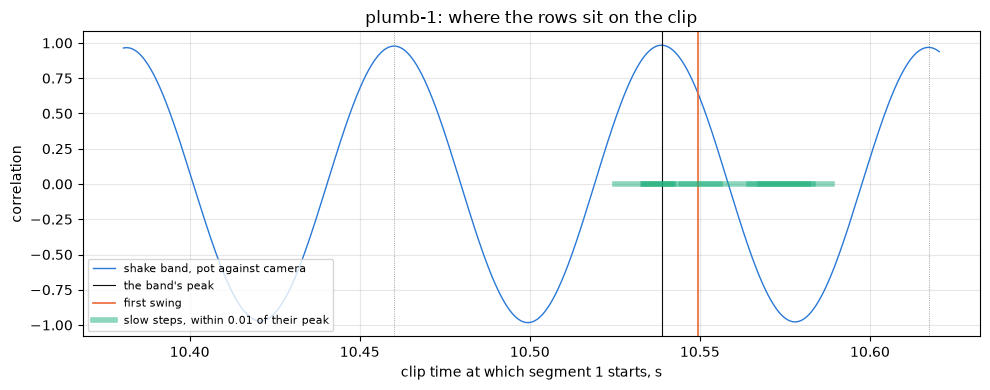

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(HOST0 - FINE1, CAM_SIGN * CF1, color=BLUE, lw=1,
        label="shake band, pot against camera")
ax.axvline(HOST0 - SHIFT1, color=INK, lw=0.8, label="the band's peak")
for d in (-PER, PER):
    ax.axvline(HOST0 - SHIFT1 - d, **figures.EDGE_STYLE)
ax.axvline(HOST0 - SHIFT1 + FIRST_SWING_MS / 1e3, color=ORANGE, lw=1.2,
           label="first swing")
for r in SLOW1:
    ax.plot([r["lo"], r["hi"]], [0.0, 0.0], color=GREEN, lw=4, alpha=0.5)
ax.plot([], [], color=GREEN, lw=4, alpha=0.5,
        label="slow steps, within 0.01 of their peak")
figures.label(ax, "clip time at which segment 1 starts, s",
              "correlation", "plumb-1: where the rows sit on the clip")
ax.legend(fontsize=8, loc="lower left")
figures.finish(fig)

What you are looking at. The band correlation (blue) as a function of where segment 1 starts on the clip. It peaks at +0.984 and peaks again one shake cycle either side at +0.968 and +0.978 (dotted), so the band alone does not pick the cycle. The first swing (orange) lands 10.6 ms from the band's peak, the pot first. The slow steps' spans (green) cover 10.52 to 10.59 s.

- Pot and horn are in phase, likely. The first swing excludes the half-cycle alternative, which would need the horn to swing 40 ms before the drive or 30 ms after it. The slow steps do not decide. Their estimates scatter 47 ms with the boxcar's length and the window, so they do not pin the phase to better than about half a cycle here.
- Stage 3 pot-table found the pot turning 7.9 ms (2.1 to 13.8) before the horn at reversals, the same order as the first swing's 10.6 ms.
- Segment 4, the 1.5 s hold, matches one cycle early on its own band. The shift of record is the chain's.

### The camera in stage 3's frame

The frames go onto the host clock by the shift, and the camera's angle is mapped into stage 3's tag frame over every frame with a row.

In [15]:
FR1["host"] = FR1.t + SHIFT1            # s, the frames on the host clock
rows_at_frames = potforce.at(HOST1, POT1, FR1.host.to_numpy())
SGN1, C1, RMS1 = potforce.map_angle(TABLE, FR1.image_deg.to_numpy(),
                                    rows_at_frames)
FR1["theta"] = SGN1 * FR1.image_deg + C1   # deg, stage 3's tag frame
FR1["T"] = TABLE.counts_at(FR1.theta.to_numpy())  # counts at the horn
print(f"2. camera into stage 3's frame: theta = {SGN1:+d} x image_deg + "
      f"{C1:.2f} deg, pot less T(theta) rms {RMS1:.2f} counts over every "
      f"frame with a row")
TH_MID1 = TABLE.angle_at(np.median(POT1[ROWS1.seg.isin(SEGS1)]))
SLOPE1 = {d: TABLE.slope_at(TH_MID1 + d) for d in (0, -2, 2)}
print(f"   the hold sits at {TH_MID1:.2f} deg; the table's local slope "
      f"there {SLOPE1[0]:.2f} counts/deg (from {SLOPE1[-2]:.2f} at -2 deg "
      f"to {SLOPE1[2]:.2f} at +2); the table's line {POT_LINE:.2f} "
      f"counts/deg")

2. camera into stage 3's frame: theta = +1 x image_deg + 90.41 deg, pot less T(theta) rms 17.66 counts over every frame with a row
   the hold sits at -88.39 deg; the table's local slope there 14.81 counts/deg (from 18.10 at -2 deg to 15.52 at +2); the table's line 18.91 counts/deg


The rms of 17.7 counts is the shake itself, which the pot reads larger than the table does at the horn. The hold sits at -88.4 degrees, on raw code 2047, 0.71 degrees wide, and the missing codes 2048 to 2058 of stage 3 pot-table. The table's local slope there is 14.8 counts per degree, against its line of 18.9.

### The harmonics

Per hold, its first 0.5 s out, the camera's best single line gives $f_0$, and a line plus five harmonics of $f_0$ is fitted to each series on its own clock. The pot in counts against the table at the horn, $T(\theta)$, and the pot through the table's inverse, $T^{-1}(\mathrm{pos})$, against the horn in degrees. The current with the window term, and the crest current without it.

In [16]:
def harmonics(t, x, f0, n=NHARM):
    # least squares of x on a line plus n harmonics of f0: (amplitude,
    # phase deg of cos(2 pi k f0 t + phase)) per harmonic, residual sd
    cols = [np.ones_like(t), t - t.mean()]
    for k in range(1, n + 1):
        w = 2 * np.pi * k * f0 * t
        cols += [np.cos(w), np.sin(w)]
    X = np.column_stack(cols)
    b, *_ = np.linalg.lstsq(X, x, rcond=None)
    out = []
    for k in range(n):
        a, s = b[2 + 2 * k], b[3 + 2 * k]
        out.append((np.hypot(a, s), np.degrees(np.arctan2(-s, a))))
    return out, float(np.std(x - X @ b))


def best_f0(t, x, lo=F0_RANGE[0], hi=F0_RANGE[1]):
    # the fundamental with the largest one-harmonic fit, 1 mHz grid
    fs = np.arange(lo, hi, 0.001)
    p = [harmonics(t, x, f, 1)[0][0][0] for f in fs]
    return float(fs[int(np.argmax(p))])

In [17]:
I_CREST1 = potforce.winding_current(ROWS1, CHAIN1, 0.0)[0]   # no window
rows_h = []
for s in SEGS1:
    m = (ROWS1.seg == s) & (ROWS1.t_seg >= SKIP_S)
    th, tp = ROWS1.host[m].to_numpy(), POT1[m]
    Ii, I0 = ROWS1.I[m].to_numpy(), I_CREST1[m.to_numpy()]
    f = FR1[(FR1.host >= th[0]) & (FR1.host <= th[-1]) & FR1.both]
    tf = f.host.to_numpy() - th[0]      # s, the frames from the hold's
    f0 = best_f0(tf, f.theta.to_numpy())
    hp, rp = harmonics(th - th[0], tp, f0)           # pot, counts
    hT, rT = harmonics(tf, f["T"].to_numpy(), f0)    # T(horn), counts
    hc, _ = harmonics(tf, f.theta.to_numpy(), f0)    # horn, deg
    hpd, _ = harmonics(th - th[0], TABLE.angle_at(tp), f0)  # pot, deg
    ok, ok0 = np.isfinite(Ii), np.isfinite(I0)
    hi_, _ = harmonics(th[ok] - th[0], Ii[ok], f0)   # current, A
    h0_, _ = harmonics(th[ok0] - th[0], I0[ok0], f0)
    rows_h.append(dict(
        seg=s, f0=f0, n=len(f), pot1=hp[0][0], T1=hT[0][0],
        pot3=hp[2][0], T3=hT[2][0], potdeg1=hpd[0][0], cam1=hc[0][0],
        potdeg3=hpd[2][0], cam3=hc[2][0], i1=hi_[0][0] * 1e3,
        i3=hi_[2][0] * 1e3, i5=hi_[4][0] * 1e3,
        i1_nowin=h0_[0][0] * 1e3, i3_nowin=h0_[2][0] * 1e3,
        ph_pot=hp[0][1], ph_T=hT[0][1], ph_i=hi_[0][1], pot5=hp[4][0],
        T5=hT[4][0], pot2=hp[1][0], T2=hT[1][0],
        se_pot=rp * np.sqrt(2 / len(tp)), se_T=rT * np.sqrt(2 / len(f))))
H1 = pd.DataFrame(rows_h)

In [18]:
H1["ratio1_counts"] = H1.pot1 / H1.T1   # pot over T(horn), fundamental
H1["ratio3_counts"] = H1.pot3 / H1.T3
H1["ratio1_deg"] = H1.potdeg1 / H1.cam1  # T^-1(pot) over the horn
H1["ratio3_deg"] = H1.potdeg3 / H1.cam3
# the amplitude's se from the residual sd, sqrt(2 / n), combined
H1["se_ratio3_counts"] = H1.ratio3_counts * np.hypot(H1.se_pot / H1.pot3,
                                                     H1.se_T / H1.T3)
H1["se_ratio1_counts"] = H1.ratio1_counts * np.hypot(H1.se_pot / H1.pot1,
                                                     H1.se_T / H1.T1)
H1["i3_over_i1"] = H1.i3 / H1.i1
H1["pot_minus_i_deg"] = ((H1.ph_i - H1.ph_pot + 180) % 360) - 180
H1["pot_minus_T_deg"] = ((H1.ph_T - H1.ph_pot + 180) % 360) - 180
print("3. harmonics per segment (last part of each hold, landing out), "
      "fundamental from the camera")
show(H1[["seg", "f0", "n", "pot1", "T1", "ratio1_counts", "pot3", "T3",
         "ratio3_counts", "potdeg1", "cam1", "ratio1_deg", "ratio3_deg"]],
     n=None)
show(H1[["seg", "se_pot", "se_T", "se_ratio1_counts",
         "se_ratio3_counts", "i1_nowin", "i3_nowin"]], n=None)
show(H1[["seg", "i1", "i3", "i5", "i3_over_i1", "pot_minus_i_deg",
         "pot_minus_T_deg", "pot2", "T2", "pot5", "T5"]], n=None)

3. harmonics per segment (last part of each hold, landing out), fundamental from the camera


,seg,f0,n,pot1,T1,ratio1_counts,pot3,T3,ratio3_counts,potdeg1,cam1,ratio1_deg,ratio3_deg
0,1,12.670,600,40.572,15.301,2.652,2.140,0.644,3.324,2.569,1.023,2.511,2.216
1,2,12.777,599,38.443,15.250,2.521,2.363,0.775,3.049,2.506,1.042,2.405,2.467
2,3,12.737,600,37.946,14.812,2.562,2.138,0.683,3.130,2.478,1.012,2.448,2.570
3,4,12.607,240,40.970,15.134,2.707,2.417,0.780,3.099,2.602,1.014,2.565,2.019


,seg,se_pot,se_T,se_ratio1_counts,se_ratio3_counts,i1_nowin,i3_nowin
0,1,0.043,0.165,0.029,0.854,284.552,113.207
1,2,0.031,0.095,0.016,0.377,281.899,112.693
2,3,0.038,0.137,0.024,0.632,278.740,102.655
3,4,0.050,0.226,0.041,0.899,286.578,121.728


,seg,i1,i3,i5,i3_over_i1,pot_minus_i_deg,pot_minus_T_deg,pot2,T2,pot5,T5
0,1,268.125,110.327,29.974,0.411,-171.130,4.034,0.890,0.283,1.015,0.079
1,2,265.376,109.407,36.405,0.412,-171.572,1.362,0.709,0.216,1.000,0.086
2,3,262.400,99.552,27.741,0.379,-170.793,3.488,0.801,0.178,0.799,0.061
3,4,270.077,118.515,40.467,0.439,-171.625,-2.850,0.758,0.193,1.292,0.037


In [19]:
LINE_RATIO1 = {}
for name, sc in (("line", POT_LINE), ("guard average", POT_GUARD)):
    LINE_RATIO1[name] = (H1.pot1 / sc) / H1.cam1   # pot by a straight line
    r = LINE_RATIO1[name]
    print(f"   ratio at the fundamental with pot / the table's {name} "
          f"({sc:.2f}): {r.min():.2f} to {r.max():.2f}")
print(f"   fundamental ratio, counts (pot / T(horn)): "
      f"{H1.ratio1_counts.min():.2f} to {H1.ratio1_counts.max():.2f}; 3rd "
      f"{H1.ratio3_counts.min():.2f} to {H1.ratio3_counts.max():.2f}")
print(f"   fundamental ratio, degrees (T^-1(pot) / horn): "
      f"{H1.ratio1_deg.min():.2f} to {H1.ratio1_deg.max():.2f}; 3rd "
      f"{H1.ratio3_deg.min():.2f} to {H1.ratio3_deg.max():.2f}")
c31, p31 = H1.cam3 / H1.cam1, H1.pot3 / H1.pot1
print(f"   current 3rd / fundamental {H1.i3_over_i1.min():.2f} to "
      f"{H1.i3_over_i1.max():.2f}; camera 3rd / fundamental "
      f"{c31.min():.3f} to {c31.max():.3f}; pot {p31.min():.3f} to "
      f"{p31.max():.3f}")

   ratio at the fundamental with pot / the table's line (18.91): 1.95 to 2.14
   ratio at the fundamental with pot / the table's guard average (19.76): 1.87 to 2.04
   fundamental ratio, counts (pot / T(horn)): 2.52 to 2.71; 3rd 3.05 to 3.32
   fundamental ratio, degrees (T^-1(pot) / horn): 2.41 to 2.56; 3rd 2.02 to 2.57
   current 3rd / fundamental 0.38 to 0.44; camera 3rd / fundamental 0.045 to 0.055; pot 0.053 to 0.061


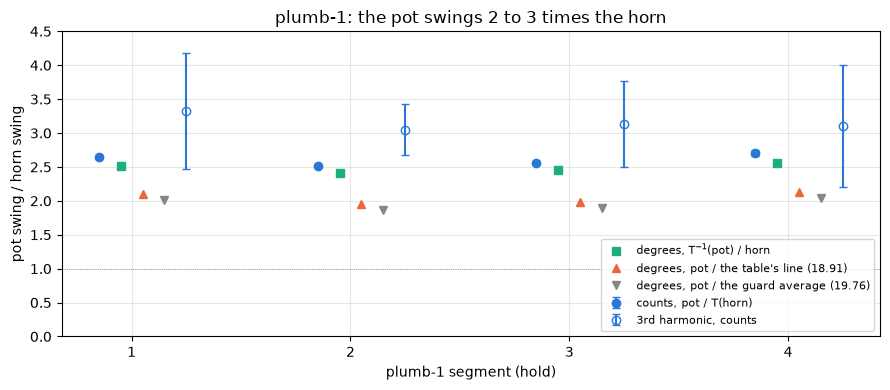

In [20]:
fig, ax = plt.subplots(figsize=(9, 4))
x = H1.seg.to_numpy()
ax.errorbar(x - 0.15, H1.ratio1_counts, yerr=H1.se_ratio1_counts, fmt="o",
            color=BLUE, capsize=figures.CAP_PT, label="counts, pot / T(horn)")
ax.plot(x - 0.05, H1.ratio1_deg, "s", color=GREEN,
        label="degrees, T$^{-1}$(pot) / horn")
ax.plot(x + 0.05, LINE_RATIO1["line"], "^", color=ORANGE,
        label=f"degrees, pot / the table's line ({POT_LINE:.2f})")
ax.plot(x + 0.15, LINE_RATIO1["guard average"], "v", color=MUTED,
        label=f"degrees, pot / the guard average ({POT_GUARD:.2f})")
ax.errorbar(x + 0.25, H1.ratio3_counts, yerr=H1.se_ratio3_counts, fmt="o",
            mfc="none", color=BLUE, capsize=figures.CAP_PT,
            label="3rd harmonic, counts")
ax.axhline(1.0, **figures.EDGE_STYLE)
ax.set_xticks(x)
ax.set_ylim(0, 4.5)
figures.label(ax, "plumb-1 segment (hold)", "pot swing / horn swing",
              "plumb-1: the pot swings 2 to 3 times the horn")
ax.legend(fontsize=8, loc="lower right")
figures.finish(fig)

What you are looking at. Per hold, the pot's swing over the horn's at the fundamental by four conversions, and at the 3rd harmonic (open circles, with their errors). A pot that read only the rotation would sit on the dotted line at 1.

- The ratio is 2.52 to 2.71 in counts and 2.41 to 2.56 in degrees through stage 3's table, in four of four holds. Confirmed above 1.9 under every conversion.
- The four holds differ by more than their noise. The band of the fundamental's ratio is 0.16 to 0.19 wide, 4 to 9 times a hold's error, a 6 % spread with no trend in time (segments 1 to 4 in degrees 2.51, 2.41, 2.45, 2.56).
- The ratio depends on how the pot is turned into degrees, since the hold sits where the table's slope runs 14.6 to 21.5 counts per degree within 3 degrees. Through the table 2.41 to 2.71, through the table's straight line 1.95 to 2.14, through the guard average 1.87 to 2.04. The table is the conversion of record, so 2.4 to 2.6 is the number, with the line's 2.0 as the lower bound if the table's fine texture did not hold at this spot.
- The 3rd harmonic's ratio, 3.05 to 3.32 in counts with errors of 0.4 to 0.9, matches the fundamental's within its error. Confirmed that it is not 3 or 9 times the fundamental's, which a wiper reading speed or acceleration would give.

### The current against the excess

The pot's excess at the fundamental, as a term on the fundamental current, and what that same term would put into the 3rd harmonic, where the current carries much more of its swing than the pot or the horn do.

In [21]:
EXC1 = H1.pot1 - H1.T1                  # counts, the excess at f0
K_I1 = EXC1 / (H1.i1 / 1e3)             # counts/A of the f0 current
NEED3 = K_I1 * H1.i3 / 1e3              # counts that term puts in the 3rd
EXC3 = H1.pot3 - H1.T3                  # counts, the excess at the 3rd
print(f"   excess at the fundamental {EXC1.min():.1f} to {EXC1.max():.1f} "
      f"counts; as counts/A of the fundamental current {K_I1.min():.0f} "
      f"to {K_I1.max():.0f}; that k on the 3rd harmonic current predicts "
      f"{NEED3.min():.1f} to {NEED3.max():.1f} counts, the pot's 3rd less "
      f"T's is {EXC3.min():.2f} to {EXC3.max():.2f}")
EXC_DEG1 = H1.potdeg1 - H1.cam1         # deg, the excess at f0
DEG_PER_A1 = EXC_DEG1 / H1.i1 * 1e3     # deg/A, window-term current
DEG_PER_A1_CREST = EXC_DEG1 / H1.i1_nowin * 1e3   # deg/A, crest current
print(f"   excess in degrees (T^-1(pot) less horn, fundamental "
      f"magnitudes) {EXC_DEG1.min():.2f} to {EXC_DEG1.max():.2f} deg; per "
      f"amp of the fundamental current {DEG_PER_A1.min():.2f} to "
      f"{DEG_PER_A1.max():.2f} deg/A (window-term current), "
      f"{DEG_PER_A1_CREST.min():.2f} to {DEG_PER_A1_CREST.max():.2f} "
      f"deg/A (crest current, no window term)")

   excess at the fundamental 23.1 to 25.8 counts; as counts/A of the fundamental current 87 to 96; that k on the 3rd harmonic current predicts 8.8 to 11.3 counts, the pot's 3rd less T's is 1.46 to 1.64
   excess in degrees (T^-1(pot) less horn, fundamental magnitudes) 1.46 to 1.59 deg; per amp of the fundamental current 5.52 to 5.88 deg/A (window-term current), 5.19 to 5.54 deg/A (crest current, no window term)


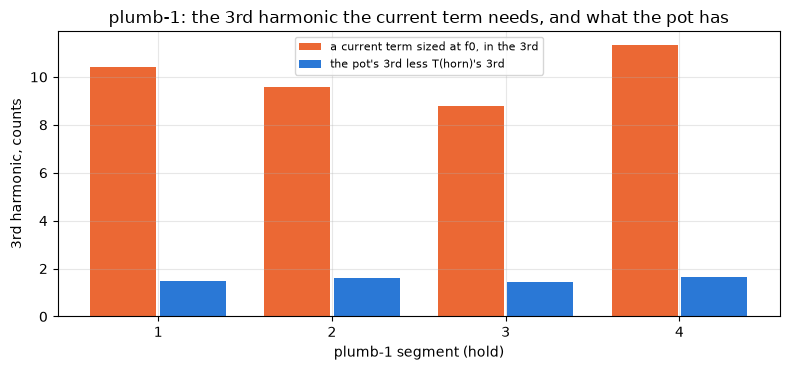

In [22]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = H1.seg.to_numpy()
ax.bar(x - 0.2, NEED3, width=0.38, color=ORANGE,
       label="a current term sized at f0, in the 3rd")
ax.bar(x + 0.2, EXC3, width=0.38, color=BLUE,
       label="the pot's 3rd less T(horn)'s 3rd")
ax.set_xticks(x)
figures.label(ax, "plumb-1 segment (hold)", "3rd harmonic, counts",
              "plumb-1: the 3rd harmonic the current term needs, and what "
              "the pot has")
ax.legend(fontsize=8)
figures.finish(fig)

What you are looking at. Per hold, the 3rd-harmonic excess a term proportional to the motor current would give if sized on the fundamental (orange), against the pot's 3rd-harmonic excess over the horn (blue).

- The window-term current's fundamental is 262 to 270 mA, the crest current's 279 to 287, the 3rd 100 to 119 (103 to 122) mA and the 5th 28 to 40 mA. The 3rd over the fundamental is 0.38 to 0.44, and the current's fundamental sits -171 degrees from the pot's.
- Sized on the fundamental, the excess of 23.1 to 25.8 counts is 87 to 96 counts per amp, 5.5 to 5.9 degrees per amp (5.2 to 5.5 on the crest current). That term on the 3rd harmonic current predicts 8.8 to 11.3 counts, and the pot's 3rd exceeds the horn's by 1.5 to 1.6. A term on the current is killed as a model of the excess. Confirmed.

### The steps at DC

The mean over whole shake cycles at the end of each hold, pot through the table's inverse against the horn, across the two goal steps.

In [23]:
lev = {}
for s in SEGS1:
    m = ROWS1.seg == s
    th = ROWS1.host[m].to_numpy()
    f0 = H1.set_index("seg").loc[s, "f0"]
    n_cyc = int((th[-1] - th[0] - SKIP_S) * f0)   # whole cycles at the end
    t1 = th[-1]
    t0 = t1 - n_cyc / f0
    mm = m & (ROWS1.host >= t0)
    f = FR1[(FR1.host >= t0) & (FR1.host <= t1) & FR1.both]
    lev[s] = (TABLE.angle_at(np.mean(POT1[mm])), f.theta.mean(),
              np.mean(POT1[mm]), f["T"].mean())
DC1 = {}
for a_, b_ in ((1, 2), (3, 4)):
    dpd = lev[b_][0] - lev[a_][0]        # deg, the pot through T^-1
    dcd = lev[b_][1] - lev[a_][1]        # deg, the horn
    DC1[f"{a_} to {b_}"] = (dpd, dcd)
    print(f"   seg {a_} -> {b_}: pot {dpd:+.3f} deg "
          f"({lev[b_][2] - lev[a_][2]:+.1f} counts), horn {dcd:+.3f} deg "
          f"(T {lev[b_][3] - lev[a_][3]:+.1f} counts); horn / pot "
          f"{dcd / dpd:.2f}")

   seg 1 -> 2: pot +0.780 deg (+11.2 counts), horn +0.801 deg (T +12.0 counts); horn / pot 1.03
   seg 3 -> 4: pot -0.758 deg (-10.9 counts), horn -0.784 deg (T -11.7 counts); horn / pot 1.03


Across both steps the horn moves 1.03 times the pot. No excess at DC, likely, from two steps of one clip. The shake's excess of 2.4 to 2.6 is at 12.7 Hz only.

### The horn tag's translation

If the output shaft shifts under the tooth force, the horn tag moves sideways in the image as well as turning. The pivot of the horn's rotation comes from the clip's two still poses, before the rows with the torque on and the arm held, and after the torque off with the arm settled. The tag's center is then predicted from the rotation about that pivot, and what is left is fitted at $f_0$. The reference tag's 25 mm side gives the image's scale.

In [24]:
ref_c = fd.corners(CORNERS1, "r").mean(axis=1)    # px, reference center
horn_c = fd.corners(CORNERS1, "h").mean(axis=1)   # px, horn tag center
model = fd.tag_model(fd.PrintScale())   # mm, the printed tag's corners
side_mm = float(np.mean(np.hypot(*(model - np.roll(model, -1,
                                                   axis=0)).T)))
PX_PER_MM = float(np.nanmedian(CORNERS1.r_side_px)) / side_mm
print(f"5. tag side {side_mm:.2f} mm, the reference's "
      f"{np.nanmedian(CORNERS1.r_side_px):.1f} px: {PX_PER_MM:.2f} px/mm")
# the still poses: whole seconds with a horn sd under STILL_SD_DEG, the
# last run of them, and the clip before the rows
t_first = HOST1[0] - SHIFT1
sd_1s = FR1.groupby((FR1.t // 1).astype(int)).theta.std()
still = sd_1s[sd_1s < STILL_SD_DEG].index.to_numpy()
last_run = [still[-1]]
for w in still[::-1][1:]:
    if w == last_run[-1] - 1:
        last_run.append(w)
    else:
        break
PRE = (FR1.t > 0.5) & (FR1.t < t_first - 0.5) & FR1.both
POST = ((FR1.t >= min(last_run) + 0.5) & (FR1.t < max(last_run) + 1)
        & FR1.both)
print(f"   still poses: clip {FR1.t[PRE].min():.1f}-{FR1.t[PRE].max():.1f}"
      f" s and {FR1.t[POST].min():.1f}-{FR1.t[POST].max():.1f} s; horn "
      f"{FR1.theta[POST].mean() - FR1.theta[PRE].mean():+.3f} deg between "
      f"them, sd within {FR1.theta[PRE].std():.3f} / "
      f"{FR1.theta[POST].std():.3f} deg")

5. tag side 25.00 mm, the reference's 170.3 px: 6.81 px/mm
   still poses: clip 0.5-10.0 s and 33.5-40.0 s; horn -3.240 deg between them, sd within 0.026 / 0.021 deg


In [25]:
REL1 = horn_c - ref_c                   # px, horn center from reference
D_ANG1 = np.radians(FR1.theta.to_numpy() * SGN1)   # the image's sense
poses = []
for msk in (PRE, POST):
    idx = np.flatnonzero(msk.to_numpy())
    poses.append((REL1[idx].mean(axis=0), D_ANG1[idx].mean(),
                  REL1[idx].std(axis=0), len(idx)))
(c1, a1, s1, n1), (c2, a2, s2, n2) = poses


def rot(x):
    # image y points down, so a positive image angle turns clockwise
    return np.array([[np.cos(x), np.sin(x)], [-np.sin(x), np.cos(x)]])


# the pivot P with c = P + R(a) (c1 - P), solved over the two poses
R12 = rot(a2 - a1)
PIVOT1 = np.linalg.solve(np.eye(2) - R12, c2 - R12 @ c1)
rng = np.random.default_rng(0)          # its sd from the poses' scatter
piv = []
for _ in range(400):
    cc1 = c1 + rng.normal(0, s1 / np.sqrt(n1))
    cc2 = c2 + rng.normal(0, s2 / np.sqrt(n2))
    piv.append(np.linalg.solve(np.eye(2) - R12, cc2 - R12 @ cc1))
PIVOT_SD1 = np.std(piv, axis=0)
r_px = np.hypot(*(c1 - PIVOT1))
print(f"   pivot from the move: {PIVOT1.round(1)} px from the reference "
      f"center, sd {PIVOT_SD1.round(2)} px (from the poses' scatter); horn "
      f"center {r_px:.1f} px = {r_px / PX_PER_MM:.2f} mm from it")

   pivot from the move: [ -4.1 429.5] px from the reference center, sd [0.05 0.02] px (from the poses' scatter); horn center 3.3 px = 0.49 mm from it


In [26]:
SHIFT_UM1 = {}
for s in SEGS1:
    m = (ROWS1.seg == s) & (ROWS1.t_seg >= SKIP_S)
    th = ROWS1.host[m].to_numpy()
    idx = FR1[(FR1.host >= th[0]) & (FR1.host <= th[-1])
              & FR1.both].index.to_numpy()
    tt = FR1.t.to_numpy()[idx]
    aa = D_ANG1[idx] - a1
    # the center the rotation alone predicts, and what is left of it
    pred = np.array([PIVOT1 + rot(x) @ (c1 - PIVOT1) for x in aa])
    resid = REL1[idx] - pred
    f0 = H1.set_index("seg").loc[s, "f0"]
    hx, _ = harmonics(tt - tt[0], resid[:, 0], f0, 1)
    hy, _ = harmonics(tt - tt[0], resid[:, 1], f0, 1)
    ha, _ = harmonics(tt - tt[0], np.degrees(aa), f0, 1)
    bound = np.hypot(*PIVOT_SD1) * np.radians(ha[0][0])
    phase = ((hx[0][1] - ha[0][1] + 180) % 360) - 180
    SHIFT_UM1[s] = (hx[0][0] / PX_PER_MM * 1e3, hy[0][0] / PX_PER_MM * 1e3,
                    phase)
    print(f"   seg {s}: horn translation x {hx[0][0]:.3f} px "
          f"({SHIFT_UM1[s][0]:.0f} um) at {phase:+.0f} deg to the "
          f"rotation, y {hy[0][0]:.3f} px ({SHIFT_UM1[s][1]:.0f} um); "
          f"rotation {ha[0][0]:.3f} deg; a pivot error of the sd gives "
          f"{bound:.3f} px")

   seg 1: horn translation x 0.465 px (68 um) at -13 deg to the rotation, y 0.089 px (13 um); rotation 1.023 deg; a pivot error of the sd gives 0.001 px
   seg 2: horn translation x 0.516 px (76 um) at -14 deg to the rotation, y 0.096 px (14 um); rotation 1.042 deg; a pivot error of the sd gives 0.001 px
   seg 3: horn translation x 0.489 px (72 um) at -14 deg to the rotation, y 0.097 px (14 um); rotation 1.012 deg; a pivot error of the sd gives 0.001 px
   seg 4: horn translation x 0.441 px (65 um) at -13 deg to the rotation, y 0.094 px (14 um); rotation 1.015 deg; a pivot error of the sd gives 0.001 px


In every hold the horn tag moves 0.44 to 0.52 px in x, 65 to 76 um at 6.81 px per mm, at -13 to -14 degrees to the rotation's phase, and 0.09 to 0.10 px in y, 13 to 14 um. The pivot's sd from the poses' scatter is 0.02 to 0.05 px, which makes 0.001 px. Read another way, the translation is what a pivot 26 px (3.8 mm) away from the two-pose pivot would make. A real side shift and a tilt of the horn out of the image plane both give it, and they are not separated here. Candidate, one clip.

The reference tag's own motion at $f_0$ is not computed in this notebook.

### The pot at the current's sign changes

The pot's mean over 1 ms after each sign change of the current less its mean over 1 ms before, inside one segment.

In [27]:
I1 = ROWS1.I.to_numpy()
sgnI = np.sign(np.where(np.isfinite(I1), I1, 0))
flips = np.flatnonzero((sgnI[1:] != sgnI[:-1]) & (sgnI[1:] != 0)
                       & (sgnI[:-1] != 0)) + 1
flips = flips[(flips > 40) & (flips < len(I1) - 40)]
segs = ROWS1.seg.to_numpy()
flips = flips[segs[flips - 20] == segs[flips + 20]]   # inside a segment
REVERSALS1 = {}
for d in (1, -1):
    f = flips[sgnI[flips] == d]
    dp = [POT1[j:j + 20].mean() - POT1[j - 20:j].mean() for j in f]
    REVERSALS1[d] = (np.mean(dp), np.std(dp, ddof=1) / np.sqrt(len(dp)),
                     len(f))
    print(f"   to {'+' if d > 0 else '-'}: {len(f)} reversals, pot after "
          f"less before {np.mean(dp):+.2f} counts (se "
          f"{REVERSALS1[d][1]:.2f})")
print(f"stage 1 pos-coupling: "
      f"{POS_COUPLING['pos_dc_coupling_counts_per_a']['value']:.2f} "
      f"counts/A DC, onset peak "
      f"{POS_COUPLING['pos_onset_peak_counts']['5v0']['value']:.1f} "
      f"counts for "
      f"{POS_COUPLING['vdd_onset_half_width_us']['5v0']['value']:.0f} us")

   to +: 44 reversals, pot after less before -2.53 counts (se 0.31)
   to -: 54 reversals, pot after less before +0.32 counts (se 0.09)
stage 1 pos-coupling: 0.56 counts/A DC, onset peak 7.0 counts for 200 us


The 98 reversals read -2.53 +/- 0.31 counts on the way to + and +0.32 +/- 0.09 on the way to -. These do not take out the shaft's own motion at the reversal, up to 3 counts per ms at this shake, so they bound nothing. Stage 1's pos-coupling is the clean bound, 0.56 counts per amp at DC and 7 counts for 200 us at a 5 V onset, so about 0.15 counts at 0.27 A against an excess of 24 counts.

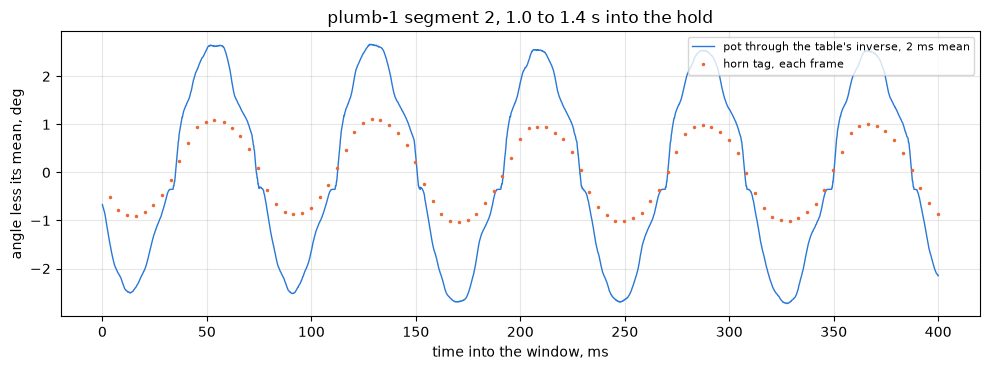

In [28]:
seg2 = ROWS1[(ROWS1.seg == 2) & ROWS1.t_seg.between(1.0, 1.4)]
f = FR1[(FR1.host >= seg2.host.iloc[0]) & (FR1.host <= seg2.host.iloc[-1])
        & FR1.both]
pot_deg = TABLE.angle_at(potforce.box(seg2.pos.to_numpy(float), BOX_ROWS))
t_ms = (seg2.host - seg2.host.iloc[0]).to_numpy() * 1e3
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(t_ms, pot_deg - np.nanmean(pot_deg), color=BLUE, lw=1,
        label="pot through the table's inverse, 2 ms mean")
ax.plot((f.host - seg2.host.iloc[0]) * 1e3, f.theta - f.theta.mean(), ".",
        color=ORANGE, ms=3, label="horn tag, each frame")
figures.label(ax, "time into the window, ms", "angle less its mean, deg",
              "plumb-1 segment 2, 1.0 to 1.4 s into the hold")
ax.legend(fontsize=8, loc="upper right")
figures.finish(fig)

What you are looking at. 0.4 s of the second hold, the pot through the table's inverse (blue) and the horn tag (orange dots) on the host clock, each about its own mean. Both swing at 12.7 Hz in phase, and the pot's swing is about two and a half times the horn's.

## holds-1, the holds near and away from the plumb

The cell of the clip run with the pot reading uncorrected, ten holds of 1.5 s. The clapper gives the clock, and the pot at each frame is its 2 ms centered mean.

In [29]:
ROWS2, META2, SEG2, BOARD2, CHAIN2, ZERO2 = potforce.load_chain(
    DATA, "holds-1", 0, G_WINDOW_S)
print(f"board {BOARD2.key}; rows {len(ROWS2)}; fw {META2['fw']}")
print(f"current zero {ZERO2['zero']:.1f} counts from "
      f"{ZERO2['n_undriven']} undriven rows")
fr2, CORNERS2, CK2 = potforce.frames(DATA, "holds-1")
print(f"clock: {CK2['flashes']} flashes, rms {CK2['rms_ms']:.2f} ms, rate "
      f"{(CK2['rate'] - 1) * 1e6:+.1f} ppm; frames {len(fr2)}, both tags "
      f"{int(fr2.both.sum())}")
HOST2, POT2 = ROWS2.host.to_numpy(), ROWS2.pos.to_numpy(float)
FR2 = fr2[fr2.both].copy()
FR2["pot"] = potforce.at(HOST2, potforce.box(POT2, BOX_ROWS),
                         FR2.host.to_numpy())
# each frame's segment, its time into it, its goal and its length
FR2["seg"] = np.interp(FR2.host, HOST2, ROWS2.seg.to_numpy(float),
                       left=np.nan, right=np.nan).round()
FR2["t_seg"] = FR2.host - FR2.seg.map(SEG2.t_start)
FR2["goal"] = FR2.seg.map(SEG2.value)
FR2["len"] = FR2.seg.map(SEG2.ms) / 1e3

board dev-v006-2A-D; rows 300000; fw 104
current zero 1212.0 counts from 12769 undriven rows


clock: 24 flashes, rms 1.09 ms, rate +12.7 ppm; frames 4301, both tags 4295


The camera goes into stage 3's frame from the plumb holds' last second, where the mean torque at the output is near zero.

In [30]:
q = FR2[FR2.goal.isin(PLUMB_GOALS) & (FR2.t_seg > FR2.len - 1.0)]
SGN2, C2, RMS2 = potforce.map_angle(TABLE, q.image_deg.to_numpy(),
                                    q.pot.to_numpy())
FR2["theta"] = SGN2 * FR2.image_deg + C2   # deg, stage 3's tag frame
FR2["T"] = TABLE.counts_at(FR2.theta.to_numpy())
print(f"camera into stage 3's frame from the plumb holds: theta = "
      f"{SGN2:+d} x image_deg + {C2:.2f} deg (pot less T rms {RMS2:.1f} "
      f"counts there, the shake in it)")

camera into stage 3's frame from the plumb holds: theta = +1 x image_deg + -268.94 deg (pot less T rms 25.0 counts there, the shake in it)


Per hold, over its last 0.5 s, the median of the pot less the table at the horn, in counts and in degrees, the mean current, and the peak to peak of the pot and of the horn. A positive $r$ means the pot reads past the horn in the + direction.

In [31]:
rows = []
for sg, g in FR2.groupby("seg"):
    sg = int(sg)
    goal = int(SEG2.loc[sg, "value"])
    w = g[g.t_seg > g.len - LAST_S]     # the hold's last 0.5 s of frames
    rr = ROWS2[(ROWS2.seg == sg)
               & (ROWS2.t_seg > SEG2.loc[sg, "ms"] / 1e3 - LAST_S)]
    rows.append(dict(
        seg=sg, goal=goal, plumb=goal in PLUMB_GOALS,
        theta=np.median(w.theta), pot=np.median(w.pot),
        horn_counts=np.median(w["T"]), r_counts=np.median(w.pot - w["T"]),
        r_deg=np.median(TABLE.angle_at(w.pot) - w.theta),
        local=TABLE.slope_at(np.median(w.theta)),
        I_ma=1e3 * np.nanmean(rr.I), pot_p2p=np.ptp(rr.pos),
        horn_p2p_counts=np.ptp(w["T"]), horn_p2p_deg=np.ptp(w.theta)))
H2 = pd.DataFrame(rows)
show(H2, n=None)

,seg,goal,plumb,theta,pot,horn_counts,r_counts,r_deg,local,I_ma,pot_p2p,horn_p2p_counts,horn_p2p_deg
0,2,1967,True,-91.184,1999.959,2000.150,-0.991,-0.048,19.887,4.254,92,30.370,1.522
1,3,2541,False,-62.328,2504.293,2512.781,-8.499,-0.557,15.724,92.154,8,0.696,0.046
2,4,1937,True,-92.451,1971.965,1973.280,-2.960,-0.131,22.346,-23.518,105,29.902,1.339
3,5,1367,False,-122.060,1431.661,1417.681,13.958,0.693,20.055,-157.047,5,1.280,0.064
4,6,1937,True,-92.410,1975.260,1974.200,-1.418,-0.063,22.272,-6.888,110,30.683,1.357
5,7,1967,True,-91.129,1999.999,2001.272,-3.699,-0.191,19.777,1.062,87,20.954,1.062
6,8,2772,False,-50.420,2737.194,2754.025,-16.824,-0.923,18.002,149.313,8,1.044,0.059
7,9,1937,True,-92.426,1968.480,1973.837,-4.515,-0.187,22.301,-17.841,107,34.289,1.524
8,10,1162,False,-131.565,1243.537,1236.786,6.729,0.300,22.654,-260.972,5,1.224,0.055
9,11,1967,True,-91.026,2006.355,2003.382,-0.374,-0.021,19.570,-1.524,87,24.779,1.261


In [32]:
FAR2 = H2[~H2.plumb].copy()
TH_PLUMB2 = H2[H2.plumb].theta.median()   # deg, the plumb holds' angle
away = np.sign(FAR2.theta - TH_PLUMB2)  # +1 on the + side of the plumb
FAR2["deg"] = FAR2.theta - TH_PLUMB2
FAR2["beyond_counts"] = -away * FAR2.r_counts   # horn beyond the pot
FAR2["beyond_deg"] = -away * FAR2.r_deg
print("far holds: horn beyond the pot away from the plumb by "
      + ", ".join(f"{v:+.1f}" for v in FAR2.beyond_counts) + " counts ("
      + ", ".join(f"{v:+.2f}" for v in FAR2.beyond_deg) + " deg) at "
      + ", ".join(f"{t:+.1f}" for t in FAR2.deg) + " deg from the plumb; "
      "hold current " + ", ".join(f"{i:+.0f}" for i in FAR2.I_ma) + " mA")
# the same as a camera scale error, and as a term per amp of the hold
FAR2["as_scale_pct"] = FAR2.beyond_deg / FAR2.deg.abs() * 100
FAR2["deg_per_a"] = FAR2.beyond_deg / (FAR2.I_ma.abs() / 1e3)
print("   as a camera scale " + ", ".join(
    f"{v:.1f}" for v in FAR2.as_scale_pct) + " % of the angle; as a term "
      "per amp of the hold current " + ", ".join(
    f"{v:.1f}" for v in FAR2.deg_per_a) + " deg/A")
PL2 = H2[H2.plumb]
print(f"plumb holds: pot p2p {PL2.pot_p2p.min():.0f} to "
      f"{PL2.pot_p2p.max():.0f} counts, horn p2p "
      f"{PL2.horn_p2p_counts.min():.0f} to {PL2.horn_p2p_counts.max():.0f}"
      f" counts by the table ({PL2.horn_p2p_deg.min():.2f} to "
      f"{PL2.horn_p2p_deg.max():.2f} deg), last 0.5 s")

far holds: horn beyond the pot away from the plumb by +8.5, +14.0, +16.8, +6.7 counts (+0.56, +0.69, +0.92, +0.30 deg) at +29.5, -30.3, +41.4, -39.8 deg from the plumb; hold current +92, -157, +149, -261 mA
   as a camera scale 1.9, 2.3, 2.2, 0.8 % of the angle; as a term per amp of the hold current 6.0, 4.4, 6.2, 1.1 deg/A
plumb holds: pot p2p 87 to 110 counts, horn p2p 21 to 34 counts by the table (1.06 to 1.52 deg), last 0.5 s


Whether the shake dies inside a hold, the peak to peak per quarter second through each plumb hold.

In [33]:
QUARTERS = np.arange(0, 1.5, 0.25)      # s, the quarters of a hold
P2P2 = {}
print("plumb holds, p2p per 250 ms (pot counts | horn deg):")
for sg in PL2.seg:
    r = ROWS2[ROWS2.seg == sg]
    g = FR2[FR2.seg == sg]
    a = [np.ptp(r.pos[(r.t_seg >= x) & (r.t_seg < x + 0.25)])
         for x in QUARTERS]
    b = [np.ptp(g.theta[(g.t_seg >= x) & (g.t_seg < x + 0.25)])
         for x in QUARTERS]
    P2P2[sg] = (a, b)
    print(f"   seg {sg}: " + ", ".join(f"{v:.0f}" for v in a) + " | "
          + ", ".join(f"{v:.2f}" for v in b))
after = [v for a, _ in P2P2.values() for v in a[1:]]
print(f"   after the landing quarter: pot {min(after):.0f} to "
      f"{max(after):.0f} counts p2p")

plumb holds, p2p per 250 ms (pot counts | horn deg):


   seg 2: 102, 90, 86, 91, 86, 92 | 1.67, 1.52, 1.22, 1.40, 1.11, 1.52
   seg 4: 625, 125, 104, 109, 105, 102 | 32.02, 2.45, 1.23, 1.39, 1.34, 1.11
   seg 6: 576, 114, 109, 95, 110, 98 | 28.81, 1.85, 1.42, 0.99, 1.36, 0.98
   seg 7: 107, 91, 88, 88, 87, 84 | 2.24, 1.22, 1.08, 1.19, 1.04, 1.01
   seg 9: 823, 131, 109, 100, 102, 103 | 42.18, 2.47, 1.70, 1.16, 1.21, 1.43
   seg 11: 783, 105, 90, 89, 87, 84 | 39.64, 1.38, 1.11, 1.10, 1.19, 1.08
   after the landing quarter: pot 84 to 131 counts p2p


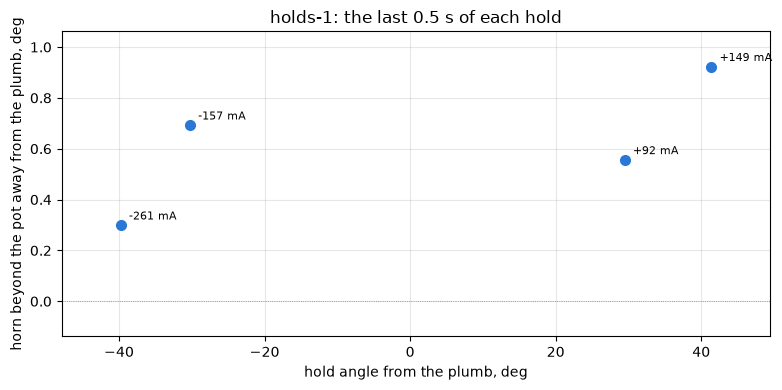

In [34]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(FAR2.deg, FAR2.beyond_deg, "o", color=BLUE, ms=7)
for _, r in FAR2.iterrows():
    ax.annotate(f"{r.I_ma:+.0f} mA", (r.deg, r.beyond_deg),
                textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.axhline(0, **figures.EDGE_STYLE)
ax.margins(x=0.1, y=0.15)
figures.label(ax, "hold angle from the plumb, deg",
              "horn beyond the pot away from the plumb, deg",
              "holds-1: the last 0.5 s of each hold")
figures.finish(fig)

What you are looking at. Per far hold, how far the horn sits beyond the pot away from the plumb, in degrees, against the hold's angle from the plumb, with the hold's current beside it.

- Far holds. The horn sits beyond the pot, away from the plumb, by 8.5, 14.0, 16.8 and 6.7 counts (0.56, 0.69, 0.92 and 0.30 degrees), the direction the motor pushes. The hold current has the sign of the side, +92, -157, +149 and -261 mA, so the motor holds the arm against gravity's pull back toward the plumb. Candidate, one run of four holds.
- As a camera scale this would be 1.9, 2.3, 2.2 and 0.8 % of the angle. As a term per amp of the hold current it would be 6.0, 4.4, 6.2 and 1.1 degrees per amp. Neither reading fits the -39.8 degree hold as well as the other three, the same hold-to-hold spread arm-1 shows.
- Plumb holds. The pot moves 87 to 110 counts peak to peak and the horn 21 to 34 counts by the table (1.06 to 1.52 degrees) over the last 0.5 s. Quarter by quarter, the shake does not die in any of the six, the pot at 84 to 131 counts peak to peak after the landing quarter. Confirmed for this cell.

## arm-1, the static term and the camera scale

Two chains in one clip, the same schedule at two velocity limits. Every frame inside a segment gets the pot's 2 ms mean and the current's 10 ms mean at its host time.

In [35]:
fr3, CORNERS3, CK3 = potforce.frames(DATA, "arm-1")
print(f"clock: {CK3['flashes']} flashes, midpoint rms {CK3['rms_ms']:.2f} "
      f"ms, rate {(CK3['rate'] - 1) * 1e6:+.1f} ppm (onset fit rms "
      f"{CK3['onset_rms_ms']:.2f} ms); frames {len(fr3)}, both tags "
      f"{int(fr3.both.sum())}")
parts = []
for k in potforce.chains(DATA, "arm-1").k:
    df, meta, seg, board, chain, zinfo = potforce.load_chain(
        DATA, "arm-1", k, G_WINDOW_S)
    vel = [x for x in meta["schedule"] if "velocity" in x][0]
    print(f"chain {k}: board {board.key}, rows {len(df)}, fw {meta['fw']},"
          f" {vel}, current zero {zinfo['zero']:.1f} from "
          f"{zinfo['n_undriven']} undriven rows")
    for s, g in df.groupby("seg"):
        if s == 0:                      # the torque-off baseline
            continue
        h = g.host.to_numpy()
        f = fr3[(fr3.host >= h[0]) & (fr3.host <= h[-1])
                & fr3.both].copy()
        f["pot"] = potforce.at(h, potforce.box(g.pos.to_numpy(float),
                                               BOX_ROWS), f.host.to_numpy())
        f["I"] = potforce.at(h, potforce.box(g.I.to_numpy(), I_MEAN_ROWS),
                             f.host.to_numpy())
        f["chain"], f["seg"] = k, s
        f["goal"] = int(seg.loc[s, "value"])
        f["t_seg"] = f.host - h[0]
        parts.append(f)
F3 = pd.concat(parts, ignore_index=True)

clock: 24 flashes, midpoint rms 0.84 ms, rate +28.4 ppm (onset fit rms 1.12 ms); frames 27873, both tags 27873
chain 0: board dev-v006-2A-D, rows 420000, fw 65, set:velocity_limit_cps=400, current zero 1212.0 from 3412 undriven rows
chain 1: board dev-v006-2A-D, rows 420000, fw 65, set:velocity_limit_cps=800, current zero 1213.0 from 4270 undriven rows


A 3 Hz zero-phase low pass takes the 13 Hz shake out of camera, pot and current, segment by segment. The camera goes into stage 3's frame over every frame, the speed is the camera angle's slope, and each frame is a hold, an "up" (moving away from the plumb) or a "down" (toward it). The plumb holds and each segment's first 0.2 s are left out of the fits.

In [36]:
def lowpass(x, hz=LP_HZ, fs=FPS["arm-1"]):
    # 2nd order Butterworth low pass, run forward and back (no delay)
    sos = butter(2, hz, fs=fs, output="sos")
    return sosfiltfilt(sos, x)


for col in ("image_deg", "pot", "I"):
    F3[col + "_lp"] = np.nan
for (k, s), g in F3.groupby(["chain", "seg"]):
    if len(g) > 30:                     # segments long enough to filter
        for col in ("image_deg", "pot", "I"):
            x = g[col].interpolate(limit_direction="both").to_numpy()
            F3.loc[g.index, col + "_lp"] = lowpass(x)
SGN3, C3, RMS3 = potforce.map_angle(TABLE, F3.image_deg_lp.to_numpy(),
                                    F3.pot_lp.to_numpy())
F3["theta0"] = SGN3 * F3.image_deg_lp + C3   # deg, refined per model
print(f"camera into stage 3's frame: theta = {SGN3:+d} x image_deg + "
      f"{C3:.2f} deg, pot less T rms {RMS3:.2f} counts (3 Hz low pass, "
      f"every frame)")
F3["v"] = np.gradient(F3.theta0, F3.host)   # deg/s, then per segment
for (k, s), g in F3.groupby(["chain", "seg"]):
    F3.loc[g.index, "v"] = np.gradient(g.theta0.to_numpy(),
                                       g.host.to_numpy())

camera into stage 3's frame: theta = +1 x image_deg + -270.74 deg, pot less T rms 10.16 counts (3 Hz low pass, every frame)


In [37]:
TH_PLUMB3 = float(np.median(F3.theta0[F3.goal == ARM_PLUMB_GOAL]))
F3["away"] = np.sign(F3.theta0 - TH_PLUMB3)   # the side of the plumb
F3["kind"] = np.where(F3.v.abs() < HOLD_DEG_S, "hold",
                      np.where(np.sign(F3.v) == F3.away, "up", "down"))
F3["blk"] = (F3.chain.astype(str) + "/" + F3.seg.astype(str) + "/"
             + (F3.t_seg // BLOCK_S).astype(int).astype(str))
Q3 = F3[(F3.goal != ARM_PLUMB_GOAL) | (F3.kind != "hold")].copy()
Q3 = Q3[(Q3.t_seg > START_S) & np.isfinite(Q3.I_lp)]
n_kind = Q3.kind.value_counts()
print(f"plumb at theta {TH_PLUMB3:.2f} deg (median over the plumb-goal "
      f"holds); quasi-static frames {len(Q3)} (holds {n_kind['hold']}, "
      f"up {n_kind['up']}, down {n_kind['down']}), angle "
      f"{Q3.theta0.min() - TH_PLUMB3:+.1f} to "
      f"{Q3.theta0.max() - TH_PLUMB3:+.1f} deg from the plumb")


def block_boot(X, y, blocks, n=N_BOOT, seed=0):
    # least squares, its sd by a bootstrap that draws whole blocks
    rng = np.random.default_rng(seed)
    b0 = np.linalg.lstsq(X, y, rcond=None)[0]
    ids, inv = np.unique(blocks, return_inverse=True)
    idx = [np.flatnonzero(inv == j) for j in range(len(ids))]
    bs = []
    for _ in range(n):
        pick = np.concatenate([idx[j] for j in
                               rng.integers(0, len(ids), len(ids))])
        bs.append(np.linalg.lstsq(X[pick], y[pick], rcond=None)[0])
    return b0, np.std(bs, axis=0), len(ids)

plumb at theta -92.60 deg (median over the plumb-goal holds); quasi-static frames 8125 (holds 3922, up 2206, down 1997), angle -39.6 to +42.4 deg from the plumb


### Gravity's share of the current

On the crawls the current is gravity's torque on the arm plus friction and a speed term, $I = A \sin(\theta - \theta_g) + F\,\mathrm{sign}(v) + B v$, with gravity's zero $\theta_g$ scanned every 0.05 degrees within 6 degrees of the plumb.

In [38]:
mv = Q3[Q3.kind != "hold"]
best = None
for th0 in np.arange(TH_PLUMB3 - 6, TH_PLUMB3 + 6, 0.05):
    X = np.column_stack([np.sin(np.radians(mv.theta0 - th0)),
                         np.sign(mv.v), mv.v])
    b = np.linalg.lstsq(X, mv.I_lp, rcond=None)[0]
    rr = float(np.sum((mv.I_lp - X @ b) ** 2))
    if best is None or rr < best[0]:
        best = (rr, th0, b)
_, TH_G3, (A3, F_C3, B_V3) = best
Xg = np.column_stack([np.sin(np.radians(mv.theta0 - TH_G3)),
                      np.sign(mv.v), mv.v])
_, SE_I3, nbk = block_boot(Xg, mv.I_lp.to_numpy(), mv.blk.to_numpy())
print(f"current on the crawls, I = A sin(theta - theta_g) + F sign(v) + "
      f"B v: theta_g {TH_G3 - TH_PLUMB3:+.2f} deg from the plumb, A "
      f"{A3 * 1e3:.1f} +/- {SE_I3[0] * 1e3:.1f} mA, F {F_C3 * 1e3:.1f} "
      f"+/- {SE_I3[1] * 1e3:.1f} mA, B {B_V3 * 1e3:.3f} mA per deg/s "
      f"({nbk} blocks)")
S3 = np.sin(np.radians(Q3.theta0 - TH_G3))   # gravity's shape per frame
print(f"   corr(sin(theta - theta_g), theta) over the fit frames "
      f"{np.corrcoef(S3, Q3.theta0)[0, 1]:.5f}")
print(f"   A as torque: {A3 * KT_GEAR:.1f} mN m through stage 3's stall Kt "
      f"(pooled), {A3 * KT_IDEAL:.1f} mN m at an ideal gear")

current on the crawls, I = A sin(theta - theta_g) + F sign(v) + B v: theta_g +2.60 deg from the plumb, A 241.7 +/- 7.3 mA, F 23.7 +/- 5.6 mA, B 1.181 mA per deg/s (48 blocks)
   corr(sin(theta - theta_g), theta) over the fit frames 0.99981
   A as torque: 53.9 mN m through stage 3's stall Kt (pooled), 86.3 mN m at an ideal gear


Gravity's zero sits 2.60 degrees from the plumb goal, and its share of the current is 241.7 +/- 7.3 mA at the full torque. As a torque that is 54 mN m through stage 3 load's stall Kt through the gears and 86 mN m at an ideal train, Ke times the counted ratio. The two bracket gravity's torque on this arm, which no result in the repo holds. Over the fit frames $\sin(\theta - \theta_g)$ and $\theta$ correlate at 0.99981, so a term on gravity's torque and a term on the angle are nearly the same column.

### Models of the residual

Each model is fitted with the camera offset refitted on a 0.01 degree grid within 1 degree of the first map, and its errors come from a bootstrap of 0.5 s blocks. The flat band is the sd of the block means of the residual.

In [39]:
def r_of(c, x=0.0):
    # r with the camera offset c and theta stretched by (1 + x) about
    # the plumb: the pot less the table at that angle, counts
    th = SGN3 * Q3.image_deg_lp.to_numpy() + c
    th = TH_PLUMB3 + (1 + x) * (th - TH_PLUMB3)
    return Q3.pot_lp.to_numpy() - TABLE.counts_at(th)


SV3, VV3 = np.sign(Q3.v.to_numpy()), Q3.v.to_numpy()
ONE3 = np.ones(len(Q3))
DESIGNS = {
    "flat: a + d sign(v) + tau v": np.column_stack([ONE3, SV3, VV3]),
    "gravity: a + b sin + d sign(v) + tau v":
        np.column_stack([ONE3, S3, SV3, VV3]),
}
CGRID3 = C3 + np.arange(-1.0, 1.0001, 0.01)
BLK3 = Q3.blk.to_numpy()

In [40]:
FITS3 = {}
for name, X in DESIGNS.items():
    best = None
    for c in CGRID3:                    # the offset that fits this model
        r = r_of(c)
        ok = np.isfinite(r)
        b = np.linalg.lstsq(X[ok], r[ok], rcond=None)[0]
        ss = np.mean((r[ok] - X[ok] @ b) ** 2)
        if best is None or ss < best[0]:
            best = (ss, c)
    c = best[1]
    r = r_of(c)
    ok = np.isfinite(r)
    b, se, nb = block_boot(X[ok], r[ok], BLK3[ok])
    res = r[ok] - X[ok] @ b
    band = pd.Series(res).groupby(BLK3[ok]).mean().std()
    FITS3[name] = dict(c=c, b=b, se=se, res=res, ok=ok, band=band)
    print(f"   {name}: c {c:.2f}; " + ", ".join(
        f"{v:+.3f} +/- {e:.3f}" for v, e in zip(b, se))
        + f"; residual sd {res.std():.2f}, flat band {band:.2f} counts, "
        f"{nb} blocks")
GRAV3 = FITS3["gravity: a + b sin + d sign(v) + tau v"]

   flat: a + d sign(v) + tau v: c -269.76; -19.262 +/- 0.907, +0.669 +/- 0.456, +0.152 +/- 0.054; residual sd 8.34, flat band 7.78 counts, 78 blocks


   gravity: a + b sin + d sign(v) + tau v: c -271.03; +7.006 +/- 0.604, -15.009 +/- 1.091, +0.574 +/- 0.300, +0.178 +/- 0.037; residual sd 5.22, flat band 4.77 counts, 78 blocks


The camera scale model stretches $\theta$ by $(1 + s)$ about the plumb, with no gravity term, scanned every 0.05 % over +/- 4 % with the offset every 0.02 degrees. Its error comes from 200 bootstrap draws of blocks, each refitted on a 0.05 % grid within 1 % of the best.

In [41]:
X = DESIGNS["flat: a + d sign(v) + tau v"]
best = None
for x in np.arange(-0.04, 0.04001, 0.0005):
    for c in C3 + np.arange(-1.0, 1.0001, 0.02):
        r = r_of(c, x)
        ok = np.isfinite(r)
        b = np.linalg.lstsq(X[ok], r[ok], rcond=None)[0]
        ss = np.mean((r[ok] - X[ok] @ b) ** 2)
        if best is None or ss < best[0]:
            best = (ss, c, x)
_, C_S3, X_S3 = best
r = r_of(C_S3, X_S3)
OK_S3 = np.isfinite(r)
b_s = np.linalg.lstsq(X[OK_S3], r[OK_S3], rcond=None)[0]
RES_S3 = r[OK_S3] - X[OK_S3] @ b_s
BAND_S3 = pd.Series(RES_S3).groupby(BLK3[OK_S3]).mean().std()

In [42]:
rng = np.random.default_rng(1)
ids, inv = np.unique(BLK3, return_inverse=True)
idx = [np.flatnonzero(inv == j) for j in range(len(ids))]
xs = []
for _ in range(200):
    pick = np.concatenate([idx[j] for j in
                           rng.integers(0, len(ids), len(ids))])
    bb = None
    for x in np.arange(X_S3 - 0.01, X_S3 + 0.01001, 0.0005):
        rr = r_of(C_S3, x)[pick]
        okp = np.isfinite(rr)
        b_ = np.linalg.lstsq(X[pick][okp], rr[okp], rcond=None)[0]
        ss = np.mean((rr[okp] - X[pick][okp] @ b_) ** 2)
        if bb is None or ss < bb[0]:
            bb = (ss, x)
    xs.append(bb[1])
SE_S3 = float(np.std(xs))
print(f"   scale: theta x (1 + s) about the plumb, a + d sign(v) + tau v: s "
      f"{X_S3 * 100:+.2f} +/- {SE_S3 * 100:.2f} %, c {C_S3:.2f}; residual "
      f"sd {RES_S3.std():.2f}, flat band {BAND_S3:.2f}")

   scale: theta x (1 + s) about the plumb, a + d sign(v) + tau v: s -1.20 +/- 0.08 %, c -271.32; residual sd 5.25, flat band 4.90


Both readings together. The gravity term refitted at fixed camera scales.

In [43]:
print("   gravity term b refitted at fixed scales s (the degeneracy):")
XG2 = DESIGNS["gravity: a + b sin + d sign(v) + tau v"]
B_AT_S3 = {}
for x in (-0.02, -0.01, 0.0, 0.01, 0.02):
    bb = None
    for c in C3 + np.arange(-1.0, 1.0001, 0.02):
        rr = r_of(c, x)
        okk = np.isfinite(rr)
        b_ = np.linalg.lstsq(XG2[okk], rr[okk], rcond=None)[0]
        ss = np.mean((rr[okk] - XG2[okk] @ b_) ** 2)
        if bb is None or ss < bb[0]:
            bb = (ss, b_, c)
    B_AT_S3[x] = (bb[1][1], np.sqrt(bb[0]))
    print(f"     s {x * 100:+.0f} %: b {bb[1][1]:+.2f} counts, residual "
          f"sd {np.sqrt(bb[0]):.2f}")
B_G3, SE_G3 = GRAV3["b"][1], GRAV3["se"][1]
B_PER_A3 = B_G3 / A3
SE_PER_A3 = abs(B_PER_A3) * np.hypot(SE_G3 / B_G3, SE_I3[0] / A3)
print(f"   gravity term in counts per A of the gravity share (b / A): "
      f"{B_PER_A3:+.1f} +/- {SE_PER_A3:.1f} counts/A")

   gravity term b refitted at fixed scales s (the degeneracy):
     s -2 %: b +10.55 counts, residual sd 5.34
     s -1 %: b -2.99 counts, residual sd 5.25
     s +0 %: b -15.04 counts, residual sd 5.22


     s +1 %: b -27.98 counts, residual sd 5.20


     s +2 %: b -41.02 counts, residual sd 5.24
   gravity term in counts per A of the gravity share (b / A): -62.1 +/- 4.9 counts/A


In [44]:
# the gravity model in degrees, r_deg = T^-1(pot) - theta, same offset
th_g = SGN3 * Q3.image_deg_lp.to_numpy() + GRAV3["c"]
rdeg = TABLE.angle_at(Q3.pot_lp.to_numpy()) - th_g
okd = np.isfinite(rdeg)
Xd = np.column_stack([ONE3, S3, SV3, VV3])[okd]
BD3, SED3, _ = block_boot(Xd, rdeg[okd], BLK3[okd])
print(f"   in degrees (T^-1(pot) less the horn, same c): b {BD3[1]:+.3f} "
      f"+/- {SED3[1]:.3f} deg at the full gravity torque, "
      f"{BD3[1] / A3:+.2f} +/- {SED3[1] / A3:.2f} deg per A of the gravity "
      f"share")

   in degrees (T^-1(pot) less the horn, same c): b -0.716 +/- 0.059 deg at the full gravity torque, -2.96 +/- 0.24 deg per A of the gravity share


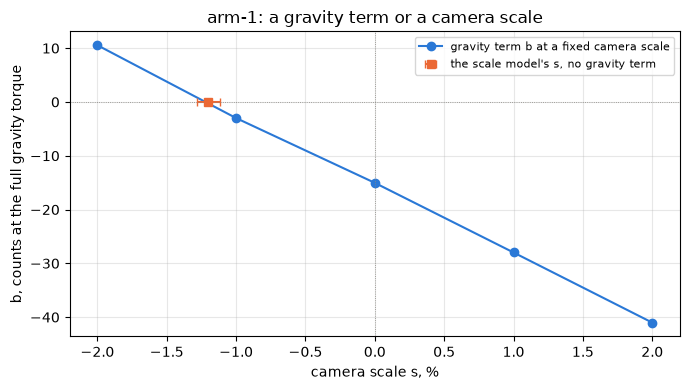

In [45]:
fig, ax = plt.subplots(figsize=(7, 4))
xs_pct = np.array(sorted(B_AT_S3)) * 100
ax.plot(xs_pct, [B_AT_S3[x][0] for x in sorted(B_AT_S3)], "o-",
        color=BLUE, label="gravity term b at a fixed camera scale")
ax.errorbar([X_S3 * 100], [0.0], xerr=[SE_S3 * 100], fmt="s",
            color=ORANGE, capsize=figures.CAP_PT,
            label="the scale model's s, no gravity term")
ax.axhline(0, **figures.EDGE_STYLE)
ax.axvline(0, **figures.EDGE_STYLE)
figures.label(ax, "camera scale s, %", "b, counts at the full gravity "
              "torque", "arm-1: a gravity term or a camera scale")
ax.legend(fontsize=8)
figures.finish(fig)

What you are looking at. The gravity term $b$ refitted with the camera scale held at five values (blue), and the scale model's own $s$ with its error (orange), a model with no gravity term, drawn at $b$ = 0. Every point fits with a residual sd of 5.20 to 5.34 counts.

- The degeneracy is confirmed. 1 % of scale moves $b$ by 13 counts (0.65 degrees) and the residual by under 0.1 count, so the two readings are equal on these data. The gravity term $b$ = -15.0 +/- 1.1 counts, -0.716 +/- 0.059 degrees at the full gravity torque, -62 +/- 5 counts per amp and -2.96 +/- 0.24 degrees per amp of the gravity share, holds only if the camera scale is exactly 1. The scale model reads s = -1.20 +/- 0.08 %.
- Both fit far better than the flat model, residual sd 5.22 and 5.25 against 8.34 counts, flat band 4.77 and 4.90 against 7.78.

### The residual by kind and by chain

In [46]:
print("per-kind block means of the residual (counts), mean / sd / n / z "
      "(z on the kind's se)")
KIND3 = {}
for label, res, okm in (("gravity", GRAV3["res"], GRAV3["ok"]),
                        ("scale", RES_S3, OK_S3)):
    bm = pd.DataFrame({"res": res, "blk": BLK3[okm],
                       "kind": Q3.kind.to_numpy()[okm],
                       "chain": Q3.chain.to_numpy()[okm]}).groupby(
        "blk").agg(res=("res", "mean"),
                   kind=("kind", lambda x: x.mode()[0]),
                   chain=("chain", "first"))
    sdb = bm.res.std()
    for kd, gk in bm.groupby("kind"):
        z = gk.res.mean() / (sdb / np.sqrt(len(gk)))
        KIND3[(label, kd)] = (gk.res.mean(), gk.res.std(), len(gk), z)
        print(f"   {label:8s} {kd:5s}: {gk.res.mean():+.2f} / "
              f"{gk.res.std():.2f} / {len(gk)} / z of the kind's mean "
              f"{z:+.1f}; blocks beyond 2 sd "
              f"{int((gk.res.abs() > 2 * sdb).sum())}")
    for ch, gk in bm.groupby("chain"):
        KIND3[(label, f"chain {ch}")] = (gk.res.mean(), len(gk))
        print(f"   {label:8s} chain {ch}: {gk.res.mean():+.2f} over "
              f"{len(gk)} blocks")

per-kind block means of the residual (counts), mean / sd / n / z (z on the kind's se)
   gravity  down : +3.26 / 4.37 / 22 / z of the kind's mean +3.2; blocks beyond 2 sd 1
   gravity  hold : -1.77 / 4.11 / 36 / z of the kind's mean -2.2; blocks beyond 2 sd 3
   gravity  up   : +1.03 / 4.61 / 20 / z of the kind's mean +1.0; blocks beyond 2 sd 0
   gravity  chain 0: -1.73 over 40 blocks
   gravity  chain 1: +2.57 over 38 blocks
   scale    down : +3.68 / 4.37 / 22 / z of the kind's mean +3.5; blocks beyond 2 sd 2
   scale    hold : -1.94 / 4.14 / 36 / z of the kind's mean -2.4; blocks beyond 2 sd 4
   scale    up   : +1.30 / 4.56 / 20 / z of the kind's mean +1.2; blocks beyond 2 sd 0
   scale    chain 0: -1.57 over 40 blocks
   scale    chain 1: +2.62 over 38 blocks


Two findings sit outside both models. The down crawls sit about 3 counts over the model (z +3.2 on the gravity model), and the faster chain sits 4.3 counts over the slower one, about 4 sigma if the 0.5 s blocks were independent, which they are not quite. The flat band of 4.8 counts is about 0.25 degrees.

### The far holds

The last 1 s of each hold at a far goal, $r$ with the scale held at 1 and the gravity model's constant taken off.

In [47]:
Q3["r1"] = r_of(GRAV3["c"]) - GRAV3["b"][0]   # counts, scale 1
rows = []
for (k, s), gg in Q3.groupby(["chain", "seg"]):
    goal = gg.goal.iloc[0]
    if goal == ARM_PLUMB_GOAL:          # the far holds only
        continue
    w = gg[(gg.t_seg > gg.t_seg.max() - 1.0)]
    if (w.kind == "hold").mean() < 0.8:  # a segment still moving at its end
        continue
    up_share = (gg.kind[:len(gg) // 3] == "up").mean()
    rows.append(dict(chain=k, seg=s, goal=goal,
                     deg=w.theta0.mean() - TH_PLUMB3, r=w.r1.mean(),
                     r_sd=w.r1.std(), I_ma=1e3 * w.I_lp.mean(),
                     arrived="up" if up_share > 0.3 else "held"))
FAR3 = pd.DataFrame(rows)
show(FAR3, n=None)
for goal, g in FAR3.groupby("goal"):
    print(f"   goal {goal}: r spreads {np.ptp(g.r):.1f} counts over "
          f"{len(g)} holds")

,chain,seg,goal,deg,r,r_sd,I_ma,arrived
0,0,4,2772,42.295,-19.232,0.102,163.401,held
1,0,6,1162,-38.943,2.539,0.108,-220.090,up
2,0,8,2772,41.804,-11.044,0.146,180.244,up
3,1,3,2772,41.682,-8.973,0.152,192.259,up
4,1,4,2772,41.685,-9.105,0.149,192.681,held
5,1,5,1162,-39.367,11.349,1.844,-176.657,held
6,1,6,1162,-39.380,11.327,0.169,-173.077,held
7,1,7,2772,41.644,-8.521,1.671,193.730,held
8,1,8,2772,41.703,-9.050,0.095,191.266,held


   goal 1162: r spreads 8.8 counts over 3 holds
   goal 2772: r spreads 10.7 counts over 6 holds


At +42 degrees the holds read -19.2, -11.0, -9.0, -9.1, -8.5 and -9.1 counts at 163 to 194 mA, and at -39 degrees +2.5, +11.4 and +11.3 at -220, -177 and -173 mA. At one angle and one gravity torque $r$ spreads 10.7 and 8.8 counts, which no model on the angle alone, scale or $b$, makes. Within the +42 degree holds $r$ rises with the current, the opposite sign to the term across angles. Likely, nine holds.

### Up less down at the same angle

The crawls away from the plumb and back toward it pass the same angles with gravity the same and the motor pushing the other way. Their difference in 2 degree bins, signed along the push away from the plumb.

In [48]:
UPDOWN3 = {}
bins = np.arange(-44, 44.001, 2.0)      # deg from the plumb
for k in sorted(Q3.chain.unique()):
    qq = Q3[(Q3.chain == k) & (Q3.kind != "hold")]
    qq = qq.assign(b=pd.cut(qq.theta0 - TH_PLUMB3, bins))
    t = qq.groupby(["b", "kind"], observed=True).agg(
        r=("r1", "mean"), I=("I_lp", "mean"), v=("v", "mean"),
        n=("r1", "size"))
    t = t[t.n >= 10].unstack("kind").dropna()   # bins with both, 10 each
    side = np.sign([iv.mid for iv in t.index])
    dr = (t["r", "up"] - t["r", "down"]) * side
    dI = (t["I", "up"] - t["I", "down"]) * side
    dv = (t["v", "up"].abs() + t["v", "down"].abs()) / 2
    UPDOWN3[k] = (dr.mean(), dr.std(), int((dr > 0).sum()), len(dr),
                  dI.mean() * 1e3, dv.mean())
    print(f"   chain {k}: {len(t)} bins; (up - down) along the push away "
          f"from the plumb: r {dr.mean():+.2f} (bin sd {dr.std():.2f}, "
          f"positive in {int((dr > 0).sum())} of {len(dr)}), I "
          f"{dI.mean() * 1e3:+.0f} mA, mean |v| {dv.mean():.1f} deg/s")

   chain 0: 36 bins; (up - down) along the push away from the plumb: r +10.69 (bin sd 4.20, positive in 36 of 36), I +102 mA, mean |v| 20.3 deg/s
   chain 1: 34 bins; (up - down) along the push away from the plumb: r +15.17 (bin sd 5.61, positive in 34 of 34), I +142 mA, mean |v| 40.6 deg/s


The same per crawl, each crawl's mean over 10 to 35 degrees from the plumb on its side, then up less down per chain and side.

In [49]:
Q3["piece"] = ((Q3.kind != Q3.kind.shift()) | (Q3.away != Q3.away.shift())
               | (Q3.seg != Q3.seg.shift())).cumsum()   # one crawl each
W3 = Q3[(Q3.kind != "hold")
        & ((Q3.theta0 - TH_PLUMB3).abs().between(10, 35))]
pc = W3.groupby("piece").agg(
    chain=("chain", "first"), kind=("kind", "first"),
    side=("away", "first"), r=("r1", "mean"), I=("I_lp", "mean"),
    v=("v", lambda x: x.abs().mean()), n=("r1", "size"))
pc = pc[pc.n > 40]                      # crawls with 40 frames or more
out = []
for k in sorted(pc.chain.unique()):
    for sd in (1, -1):
        u = pc[(pc.chain == k) & (pc.side == sd) & (pc.kind == "up")]
        d = pc[(pc.chain == k) & (pc.side == sd) & (pc.kind == "down")]
        if len(u) and len(d):
            out.append(dict(chain=k, side=sd,
                            dr=sd * (u.r.mean() - d.r.mean()),
                            dI=sd * (u.I.mean() - d.I.mean()),
                            v=(u.v.mean() + d.v.mean()) / 2,
                            n_up=len(u), n_down=len(d)))
D3 = pd.DataFrame(out)
D3["dr_over_dI"] = D3.dr / D3.dI
show(pc, n=None)
show(D3, n=None)

,chain,kind,side,r,I,v,n
piece,,,,,,,
2,0,up,1.000,-2.239,0.133,20.098,299
5,0,down,1.000,-9.149,0.041,20.603,291
6,0,up,-1.000,-7.264,-0.126,17.828,98
7,0,up,-1.000,-0.593,-0.186,20.942,146
9,0,down,-1.000,11.165,-0.049,20.624,291
10,0,up,1.000,5.450,0.093,18.463,126
11,0,up,1.000,4.502,0.181,20.696,118
13,0,down,1.000,-5.000,0.039,20.842,288
18,1,up,1.000,6.237,0.134,40.665,148


,chain,side,dr,dI,v,n_up,n_down,dr_over_dI
0,0,1,9.645,0.096,20.237,3,2,100.994
1,0,-1,15.093,0.107,20.005,2,1,140.745
2,1,1,11.257,0.136,41.830,2,2,82.809
3,1,-1,20.960,0.172,41.223,1,1,122.035


In [50]:
for k, gk in D3.groupby("chain"):
    print(f"   chain {k}: dr {gk.dr.mean():+.1f}, dI "
          f"{gk.dI.mean() * 1e3:+.0f} mA, dr/dI "
          f"{gk.dr_over_dI.mean():.0f} counts/A, |v| {gk.v.mean():.1f} "
          "deg/s")
# two readings: dr = k dI through the origin, or dr = d0 + tau dv with
# dv = 2 |v| in counts/s at the table's line
K_UD3 = np.sum(D3.dr * D3.dI) / np.sum(D3.dI ** 2)
RMS_K3 = np.sqrt(np.mean((D3.dr - K_UD3 * D3.dI) ** 2))
Xt = np.column_stack([np.ones(len(D3)), 2 * D3.v * POT_LINE])
BT3 = np.linalg.lstsq(Xt, D3.dr, rcond=None)[0]
RMS_T3 = np.sqrt(np.mean((D3.dr - Xt @ BT3) ** 2))
print(f"   k through the origin {K_UD3:.0f} counts/A, residual rms "
      f"{RMS_K3:.2f} counts; d0 {BT3[0]:+.1f} counts + tau "
      f"{BT3[1] * 1e3:.1f} ms, residual rms {RMS_T3:.2f} ({len(D3)} side "
      f"pairs)")

   chain 0: dr +12.4, dI +101 mA, dr/dI 121 counts/A, |v| 20.1 deg/s
   chain 1: dr +16.1, dI +154 mA, dr/dI 102 counts/A, |v| 41.5 deg/s
   k through the origin 112 counts/A, residual rms 2.71 counts; d0 +9.1 counts + tau 4.4 ms, residual rms 3.97 (4 side pairs)


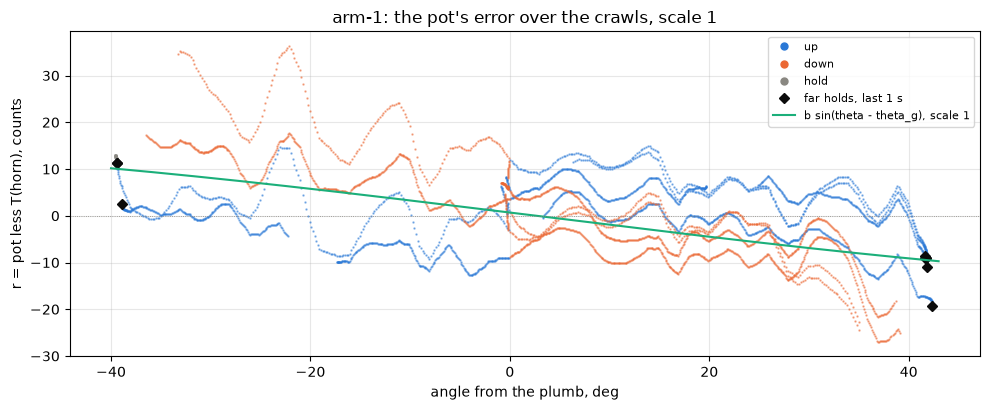

In [51]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for kind, color in (("up", BLUE), ("down", ORANGE), ("hold", MUTED)):
    g = Q3[Q3.kind == kind]
    ax.plot(g.theta0 - TH_PLUMB3, g.r1, ".", ms=1.5, color=color,
            alpha=0.5)
    ax.plot([], [], "o", ms=5, color=color, label=kind)   # legend entry
ax.plot(FAR3.deg, FAR3.r, "D", color=INK, ms=5, label="far holds, last 1 s")
grid = np.linspace(-40, 43, 200)
ax.plot(grid, GRAV3["b"][1] * np.sin(np.radians(grid + TH_PLUMB3 - TH_G3)),
        color=GREEN, lw=1.5, label="b sin(theta - theta_g), scale 1")
ax.axhline(0, **figures.EDGE_STYLE)
figures.label(ax, "angle from the plumb, deg", "r = pot less T(horn), "
              "counts", "arm-1: the pot's error over the crawls, scale 1")
ax.legend(fontsize=8, loc="upper right")
figures.finish(fig)

What you are looking at. Every quasi-static frame of arm-1, the pot less the table at the horn with the camera scale at 1, against the angle from the plumb, colored by whether the arm was moving away from the plumb (up), toward it (down) or holding. The far holds' last second is in black, and the green line is the gravity model's term alone.

- The up crawls read above the down crawls at the same angle, along the push away from the plumb, by +10.7 counts on chain 0 (bin sd 4.2, positive in 36 of 36 bins) at a current difference of +102 mA and 20 degrees per second, and by +15.2 counts on chain 1 (sd 5.6, 34 of 34) at +142 mA and 41 degrees per second. Confirmed that the difference is real.
- Its sign is the opposite of the static term's. More current in the push's direction reads the pot further along the push. Per crawl and side, from 10 to 35 degrees out, $dr/dI$ is 101, 141, 83 and 122 counts per amp. As $k\,dI$ through the origin it is 112 counts per amp (residual 2.7 counts), and as a timing term $d_0 + \tau\,dv$ it is +9.1 counts plus 4.4 ms (residual 4.0), over 4 side pairs. The cause is open.

### The plumb holds

The last 1 s of the plumb holds, the camera's largest line in 8 to 20 Hz, and the pot's and the table's rms about a line.

In [52]:
PLUMB3 = []
for (k, s), gg in F3[F3.goal == ARM_PLUMB_GOAL].groupby(["chain", "seg"]):
    w = gg[gg.t_seg > gg.t_seg.max() - 1.0]
    th = SGN3 * w.image_deg.to_numpy() + GRAV3["c"]
    Tc = TABLE.counts_at(th)
    pot = w.pot.to_numpy()
    tt = w.host.to_numpy()
    x = th - th.mean()
    fs_ = np.arange(8, 20, 0.01)        # Hz, the camera's largest line
    pw = [abs(np.sum(x * np.exp(-2j * np.pi * f * tt))) for f in fs_]
    f0 = fs_[int(np.argmax(pw))]
    dp = pot - np.polyval(np.polyfit(tt, pot, 1), tt)
    dT = Tc - np.polyval(np.polyfit(tt, Tc, 1), tt)
    PLUMB3.append(dict(chain=k, seg=s, hz=f0, pot_rms=dp.std(),
                       horn_rms=dT.std(), ratio=dp.std() / dT.std(),
                       horn_deg=th.std()))
    print(f"   chain {k} seg {s}: {f0:.2f} Hz, pot rms {dp.std():.1f}, "
          f"T(horn) rms {dT.std():.1f}, ratio {dp.std() / dT.std():.2f}, "
          f"horn rms {th.std():.2f} deg")
PLUMB3 = pd.DataFrame(PLUMB3)

   chain 0 seg 2: 14.42 Hz, pot rms 23.6, T(horn) rms 6.2, ratio 3.78, horn rms 0.27 deg


   chain 0 seg 9: 14.05 Hz, pot rms 31.7, T(horn) rms 12.4, ratio 2.55, horn rms 0.53 deg
   chain 1 seg 2: 13.88 Hz, pot rms 31.9, T(horn) rms 10.3, ratio 3.10, horn rms 0.44 deg
   chain 1 seg 9: 13.92 Hz, pot rms 30.6, T(horn) rms 8.8, ratio 3.50, horn rms 0.38 deg


At 13.9 to 14.4 Hz the pot moves 23.6 to 31.9 counts rms and the table at the horn 6.2 to 12.4, a ratio of 2.55 to 3.78 over 4 holds. The same effect as plumb-1, with a larger spread, the horn's rms being 0.27 to 0.53 degrees, about half of plumb-1's.

## The free horn, stage 3 pot-table's sitting

Stage 3 pot-table's crawl clips, re-read through `potforce.free_frames`. Each crawl hold ends with the drive on, then coasts for 300 ms with the bridge open, so the current drops to zero. Where the hold had stalled, under 1 degree per second over its last 120 ms, the horn does not move across the release, and the pot less the table at the tag across it is a current term with the table, its texture and the stamps all cancelled. The pot is the 16-row mean at the row under each frame on the camera-aligned clock, and the current the 10 ms mean, with each chain's zero from its coasts.

In [53]:
FE, PF_FREE, FREE_INFO = potforce.free_frames(PAIR_DIR, KNOT_DEG,
                                              POT_LINE, G_WINDOW_S)
print(f"{len(FE)} frames over {FE.sid.nunique()} segments of "
      f"{FE['clip'].nunique()} clips; board {FREE_INFO['board']}, window "
      f"term {FREE_INFO['g_s'] * 1e3:.3f} mS, trough less coast "
      f"{FREE_INFO['trough_less_coast']:.2f} counts")

11271 frames over 122 segments of 10 clips; board dev-v006-2A-D, window term 3.933 mS, trough less coast 0.66 counts


In [54]:
def free_pairs(fe):
    # each crawl's hold end (last 120 ms) against its coast's end (last
    # 100 ms), per clip, chain and direction
    f = fe[fe["rc"].notna()]
    rows = []
    for (clip, k, gd), g in f[f["kind"] == "crawl"].groupby(
            ["clip", "k", "gd"]):
        h, c = g[g["label"] == "crawl"], g[g["label"] == "coast"]
        if h.empty or c.empty:
            continue
        h = h[h["t_seg"] > h["seg_len"] - HOLD_END_S]
        c = c[c["t_seg"] > c["seg_len"] - COAST_END_S]
        rows.append(dict(
            clip=clip, k=k, gd=gd, duty=h["duty_pct"].median(),
            n_hold=len(h), n_coast=len(c), rc_hold=h["rc"].mean(),
            rc_coast=c["rc"].mean(),
            d_rc=h["rc"].mean() - c["rc"].mean(), I=h["I"].mean(),
            v_hold=h["speed"].mean(), v_hold_abs=h["speed"].abs().mean(),
            v_coast=c["speed"].mean(),
            d_pos=c["box16"].mean() - h["box16"].mean(),
            d_tag=c["image_deg"].mean() - h["image_deg"].mean(),
            sd_hold=h["rc"].std(), sd_coast=c["rc"].std()))
    return pd.DataFrame(rows)


PAIRS4 = free_pairs(FE)
STALLS4 = PAIRS4[PAIRS4["v_hold_abs"] < STALL_DEG_S].copy()
show(STALLS4[["clip", "k", "gd", "duty", "n_hold", "n_coast", "I",
              "v_hold", "d_pos", "d_tag", "rc_hold", "rc_coast", "d_rc",
              "sd_hold", "sd_coast"]], n=None)

,clip,k,gd,duty,n_hold,n_coast,I,v_hold,d_pos,d_tag,rc_hold,rc_coast,d_rc,sd_hold,sd_coast
0,crawl-0-0,0,-1.000,6.000,21,18,-0.055,-0.126,0.131,-0.021,1.598,2.149,-0.551,0.232,0.269
1,crawl-0-0,0,1.000,6.000,21,17,0.055,0.232,0.129,0.005,3.055,3.099,-0.044,0.271,0.215
3,crawl-0-0,1,1.000,7.000,21,17,0.064,0.095,0.081,-0.011,-0.399,-0.092,-0.307,0.319,0.339
5,crawl-0-0,2,1.000,8.000,21,15,0.075,0.090,0.116,-0.013,1.303,1.731,-0.428,0.409,0.354
10,crawl-1-0,5,-1.000,6.000,20,18,-0.055,0.067,-0.028,0.041,-1.524,-2.290,0.766,0.359,0.301
11,crawl-1-0,5,1.000,6.000,21,15,0.055,-0.002,0.080,-0.001,0.217,0.320,-0.102,0.250,0.365


In [55]:
I4, Y4 = STALLS4["I"].to_numpy(), STALLS4["d_rc"].to_numpy()
B4 = (I4 @ Y4) / (I4 @ I4)              # d_rc = -k I through the origin
RES4 = Y4 - B4 * I4
SE4 = np.sqrt(RES4 @ RES4 / (len(Y4) - 1) / (I4 @ I4))
K_FREE4 = -B4                           # counts/A
print(f"k (stalls, through the origin) {K_FREE4:+.1f} +/- {SE4:.1f} "
      f"counts/A over {len(Y4)} stalls; residual sd "
      f"{RES4.std(ddof=1):.2f} counts")
print(f"   as degrees per amp at the table's line {K_FREE4 / POT_LINE:+.2f} "
      f"+/- {SE4 / POT_LINE:.2f} deg/A")
print(f"   mean |d_rc| {np.abs(Y4).mean():.2f} counts, signed along the "
      f"drive {np.mean(Y4 * np.sign(I4)):+.2f} +/- "
      f"{np.std(Y4 * np.sign(I4), ddof=1) / np.sqrt(len(Y4)):.2f}")
print(f"   across the release: tag {STALLS4.d_tag.min():+.3f} to "
      f"{STALLS4.d_tag.max():+.3f} deg, pot {STALLS4.d_pos.min():+.2f} to "
      f"{STALLS4.d_pos.max():+.2f} counts; current "
      f"{1e3 * STALLS4.I.abs().min():.0f} to "
      f"{1e3 * STALLS4.I.abs().max():.0f} mA")

k (stalls, through the origin) +3.3 +/- 2.9 counts/A over 6 stalls; residual sd 0.43 counts
   as degrees per amp at the table's line +0.17 +/- 0.16 deg/A
   mean |d_rc| 0.37 counts, signed along the drive -0.18 +/- 0.18
   across the release: tag -0.021 to +0.041 deg, pot -0.03 to +0.13 counts; current 55 to 75 mA


What plumb-1's term on the current would read at these stalls, at its smallest size per amp, for comparison.

In [56]:
k_plumb = DEG_PER_A1.min()              # deg/A, plumb-1's smallest
pred_deg = k_plumb * np.abs(I4)         # deg a current term would read
pred_counts = pred_deg * POT_LINE       # counts at the table's line
z = pred_counts / RES4.std(ddof=1)      # in residual sds
print(f"at {k_plumb:.2f} deg/A the stalls would read {pred_deg.min():.2f} "
      f"to {pred_deg.max():.2f} deg ({pred_counts.min():.1f} to "
      f"{pred_counts.max():.1f} counts), {z.min():.0f} to {z.max():.0f} "
      f"residual sd away")

at 5.52 deg/A the stalls would read 0.30 to 0.42 deg (5.7 to 7.9 counts), 13 to 18 residual sd away


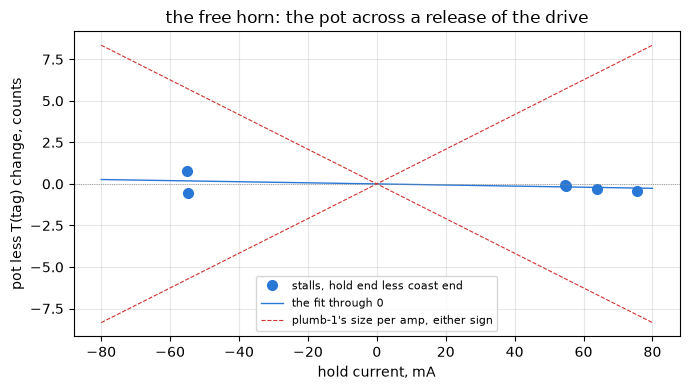

In [57]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(I4 * 1e3, Y4, "o", color=BLUE, ms=7,
        label="stalls, hold end less coast end")
ii = np.linspace(-0.08, 0.08, 50)
ax.plot(ii * 1e3, B4 * ii, color=BLUE, lw=1, label="the fit through 0")
for sgn in (1, -1):
    ax.plot(ii * 1e3, sgn * k_plumb * POT_LINE * ii, **figures.HIGHLIGHT_STYLE,
            label="plumb-1's size per amp, either sign" if sgn > 0 else None)
ax.axhline(0, **figures.EDGE_STYLE)
figures.label(ax, "hold current, mA", "pot less T(tag) change, counts",
              "the free horn: the pot across a release of the drive")
ax.legend(fontsize=8)
figures.finish(fig)

What you are looking at. For each of the six stalled crawl holds, the pot less the table at the tag at the hold's end less the same at the coast's end, against the hold's current, with the fit through zero (blue) and what plumb-1's term per amp would read, either sign (red dashed).

- The horn did not move across the release, the tag by -0.021 to +0.041 degrees and the pot by -0.03 to +0.13 counts.
- Hold end less coast end reads -0.55, -0.04, -0.31, -0.43, +0.77 and -0.10 counts. Through the origin $k_\mathrm{free}$ ("k free") = +3.3 +/- 2.9 counts per amp (residual sd 0.43 counts), 0.17 +/- 0.16 degrees per amp. Confirmed.
- At plumb-1's 5.5 degrees per amp these stalls would read 0.30 to 0.42 degrees, 5.7 to 7.9 counts, 13 to 18 residual sds away. So the pot does not read the motor current. The free horn's 60 mA goes into the train's own friction, upstream of the last mesh, and the output carries only the pot's and the bearing's drag. The tooth-torque model predicts nothing here, as seen. Likely as the reading, confirmed as the number.

All 30 crawl hold ends against their coast rests, the moving ones included, with a speed term per clip.

In [58]:
mv4 = PAIRS4[PAIRS4["v_hold_abs"] >= STALL_DEG_S].copy()
allp = pd.concat([STALLS4, mv4])
X = [np.ones(len(allp)), allp["I"].to_numpy()]
names = ["c", "k"]
for cl in sorted(allp["clip"].unique()):
    # the speed in counts per ms, so tau comes out in ms
    X.append(np.where(allp["clip"] == cl,
                      allp["v_hold"].to_numpy() * POT_LINE / 1000, 0.0))
    names.append(f"tau[{cl}]")
X = np.column_stack(X)
yy = allp["d_rc"].to_numpy()
beta, *_ = np.linalg.lstsq(X, yy, rcond=None)
r = yy - X @ beta
dof = len(yy) - X.shape[1]
se = np.sqrt(np.diag(np.linalg.inv(X.T @ X) * (r @ r) / dof))
ALL4 = {}
print(f"all {len(allp)} crawl hold ends vs their coast rests, "
      f"d_rc = c - k I + tau_clip v ({dof} dof):")
for n_, b_, s_ in zip(names, beta, se):
    ALL4[n_] = (-b_ if n_ == "k" else b_, s_)
    print(f"  {n_:20s} {ALL4[n_][0]:+8.2f} +/- {s_:.2f}")
print(f"  residual sd {np.sqrt(r @ r / dof):.2f} counts")

all 30 crawl hold ends vs their coast rests, d_rc = c - k I + tau_clip v (22 dof):
  c                       -0.66 +/- 0.43
  k                       -3.95 +/- 14.72
  tau[crawl-0-0]         +12.85 +/- 4.19
  tau[crawl-0-1]         +12.74 +/- 1.95
  tau[crawl-1-0]         +18.99 +/- 2.96
  tau[crawl-1-1]         +13.55 +/- 1.55
  tau[crawl-2-0]          -1.58 +/- 3.06
  tau[crawl-2-1]          -1.70 +/- 1.72
  residual sd 2.22 counts


Over all 30 the current term is $k$ = -4 +/- 15 counts per amp. The timing term is +12.7 to +19.0 ms on four clips and -1.6 to -1.7 ms on the other two, so it changes between clips.

The pot and the tag across the release, the six stalls pooled, signed along each drive.

In [59]:
out = []
for _, s in STALLS4.iterrows():
    g = FE[(FE["clip"] == s["clip"]) & (FE["k"] == s["k"])
           & (FE["gd"] == s["gd"])]
    hold, coast = g[g["label"] == "crawl"], g[g["label"] == "coast"]
    t0 = coast["host"].min()            # s, the coast's start
    both = pd.concat([hold, coast])
    both = both[(both["host"] > t0 - 0.06) & (both["host"] < t0 + 0.10)]
    out.append(both.assign(
        t_ms=(both["host"] - t0) * 1e3, rcs=both["rc"] * s["gd"],
        dpos=(both["box16"] - hold["box16"].iloc[-20:].mean()) * s["gd"],
        dtag=(both["image_deg"] - hold["image_deg"].iloc[-20:].mean())
        * s["gd"]))
o = pd.concat(out)
o["bin"] = pd.cut(o["t_ms"], [-60, -40, -20, 0, 10, 20, 40, 60, 100])
show(o.groupby("bin", observed=True).agg(
    n=("rcs", "size"), pos_counts=("dpos", "mean"),
    tag_deg=("dtag", "mean"), rc_along=("rcs", "mean"),
    I_mA=("I_inst", lambda x: 1e3 * x.abs().mean())).reset_index(),
    n=None)

,bin,n,pos_counts,tag_deg,rc_along,I_mA
0,"(-60, -40]",23,0.069,0.001,0.746,60.772
1,"(-40, -20]",19,0.030,0.000,0.529,58.362
2,"(-20, 0]",6,0.175,0.002,0.843,NaN
3,"(0, 10]",8,0.023,-0.007,0.861,NaN
4,"(10, 20]",8,0.093,-0.016,1.130,NaN
5,"(20, 40]",21,0.048,-0.017,1.227,NaN
6,"(40, 60]",22,0.090,-0.011,1.078,NaN
7,"(60, 100]",41,0.026,-0.014,0.936,NaN


Across the release the pot moves by under 0.2 counts and the tag by under 0.02 degrees, bin by bin.

## Quoted from stage 3's results

The lash by hand of stage 3 pot-table and the load steps of stage 3 load, read from their result files and not recomputed.

In [60]:
def quoted(d, key):
    v = d[key]
    print(f"   {key}: {v['value']:.4g} [{v['lo']:.4g}, {v['hi']:.4g}] "
          f"{v['unit']}")


print("pot-table, the lash by hand (finger-rocked horn, motor still):")
for k in ("pot_hand_ratio", "pot_force_excess_deg", "pot_force_relax_deg",
          "lash_hand_deg", "pot_before_horn_ms", "stamp_lead_ms_range"):
    quoted(POT3, k)
print("   rocks per spot", POT3["lash_hand_rocks"])
print("load, the +/- 5 % steps with the output held still:")
for k in ("pot_torque_coupling_deg_per_50ma", "steps_k_i_jump_ma_per_pct"):
    quoted(LOAD, k)
c = LOAD["pot_torque_coupling_deg_per_50ma"]
SWING_A = 2 * 5 * LOAD["steps_k_i_jump_ma_per_pct"]["value"] / 1e3
err = c["hi"] - c["value"]
STEPS_DEG_PER_A = (c["value"] / SWING_A, err / SWING_A)
print(f"   over the {SWING_A * 1e3:.0f} mA between +5 % and -5 %: "
      f"{STEPS_DEG_PER_A[0]:+.2f} +/- {STEPS_DEG_PER_A[1]:.2f} deg/A "
      f"({abs(c['value'] / err):.1f} sigma)")

pot-table, the lash by hand (finger-rocked horn, motor still):
   pot_hand_ratio: 1.759 [1.664, 1.899] ratio
   pot_force_excess_deg: 1.018 [0.982, 1.073] deg
   pot_force_relax_deg: 0.3084 [0.2422, 0.3616] deg
   lash_hand_deg: 1.236 [1.154, 1.319] deg
   pot_before_horn_ms: 7.938 [2.068, 13.81] ms
   stamp_lead_ms_range: 2.615 [-4.088, 28.71] ms
   rocks per spot {'mid': 16, 'low': 13, 'high': 9, 'after, -53 deg': 14, 'after, -90 deg': 7}
load, the +/- 5 % steps with the output held still:
   pot_torque_coupling_deg_per_50ma: -0.1064 [-0.1881, -0.02475] deg
   steps_k_i_jump_ma_per_pct: 9.926 [9.546, 10.31] mA/%
   over the 99 mA between +5 % and -5 %: -1.07 +/- 0.82 deg/A (1.3 sigma)


- The lash by hand, a finger-rocked horn with the motor still, 59 rocks at five spots. The pot moves 1.76 (1.66 to 1.90) times the tag, and at the held ends it sits 1.02 degrees (0.98 to 1.07) past the horn in the push's direction, relaxing 0.31 degrees (0.24 to 0.36) while held. Confirmed in stage 3. The finger's torque was not measured, so it gives the sign and the relaxation but no $c$.
- The load steps, +/- 5 % with the output held still by friction. Stage 3 load reads the pot moving -0.094 degrees on average for +5 % and +0.012 for -5 %. Its key `pot_torque_coupling_deg_per_50ma` holds the difference of the two step directions, -0.106 +/- 0.082 degrees, 1.3 sigma, and not a value per 50 mA. Over the 99 mA between the two steps that is -1.07 +/- 0.82 degrees per amp, not a finding. Its sign is the static term's.

## Signs, all routes

The frame is + in the direction positive duty drives, and $\tau_\mathrm{out} > 0$ means the gear pushes the horn in +. The reading error is the pot less the horn.

| route | $\tau_\mathrm{out}$ | reading error | sign of $c$ |
|---|---|---|---|
| far hold, + side (holds-1, arm-1) | + (holds the arm against gravity) | - (the pot behind the push) | - |
| far hold, - side | - | + | - |
| shake (plumb-1) | $-J\alpha$, out of phase with $\theta$ | + in phase with $\theta$ (the pot 2.5 times the horn, in phase) | - |
| finger push + (the lash by hand) | - (the train resists the finger) | + (the pot past the horn) | - |
| load steps +5 % | + | - (1.3 sigma) | - |
| up less down (arm-1) | + more on the way up | + | + (so not this term) |

Here $J$ ("J") is the arm's inertia and $\alpha$ ("alpha") its angular acceleration. Every route that carries a load change at the output gives one sign of $c$. Likely. The up-down difference is the odd one, and it is not the force term.

## Alternatives for the excess

| alternative | for | against | verdict |
|---|---|---|---|
| rolling shutter | a phone | the tag spans 8.5 % of the rows, under 0.35 ms of skew, 0.03 degrees at the shake's peak speed | killed |
| motion blur | 240 fps | an exposure under 4.2 ms loses 0.5 % at 12.7 Hz | killed |
| the body or the phone moving | | a body that turned would make the camera read more, not less | killed (the reference tag's motion at $f_0$ is not computed here) |
| the lens or the view | a landscape lens on portrait clips in the first tracking | re-tracked with the portrait lens, the shake's rms moved -0.24 % and the scale under 0.1 %. DC horn over pot 1.03 against 2.4 to 2.6 at the shake | killed for the shake's ratio |
| horn or arm flex, spline slop, the tag on the arm | | every point of a torsional chain from a nearly still rotor moves at most as much as the arm. Statically a compliance between the pot's shaft and the horn would put the horn closer to the plumb than the pot under gravity, and the far holds read the horn beyond the pot (holds-1, arm-1) | killed, likely |
| the table's slope at code 2047 | the hold sits on code 2047 and the missing 2048 to 2058 | the ratio is 1.9 or more under each of three conversions, and the DC steps read 1.03 | killed as the gain. It sets the 2.0 against 2.5 spread |
| the drive coupling electrically into the pot | | stage 1 pos-coupling, 0.56 counts per amp and 7 counts for 200 us at an onset, 0.15 counts at 0.27 A against 24 | killed |
| the wiper reading speed or acceleration | | would make the 3rd's ratio 3 or 9 times the fundamental's, and it matches within its error | killed |
| a term on the motor current | the fundamental fits 5.5 degrees per amp | the 3rd needs 8.8 to 11.3 counts and has 1.5. The free horn reads 0.17 +/- 0.16 degrees per amp | killed |
| a term on the torque at the last mesh | a flat harmonic ratio (the spring torque follows the arm with the rotor nearly still), one sign of $c$ over four routes, the horn tag shifting 65 to 76 um in step, the free horn's null | the size per unit of load is unsettled | likely as the term, candidate as the mechanism |

The rolling shutter and the blur rows are bounds from the clips' geometry and rate, not computed in this notebook.

## Validity envelope

Where the term is and is not seen.

| setting | load at the last mesh | seen | size |
|---|---|---|---|
| free horn, crawl stalls (pot-table) | the pot's and the bearing's drag only | no | 0.17 +/- 0.16 degrees per amp of motor current |
| finger rock, motor still (the lash by hand) | the finger's push, the train back-driven | yes | 1.02 degrees past, relaxing 0.31 degrees while held |
| arm at the plumb, the 12.7 Hz shake (plumb-1, arm-1's plumb holds) | the arm's inertia, crossing zero | yes | the pot 2.4 to 2.6 times the horn (plumb-1), 2.6 to 3.8 times (arm-1) |
| arm at the DC steps near the plumb (plumb-1) | small and slow | no excess | horn over pot 1.03 |
| arm at the far holds, static (holds-1, arm-1) | gravity, one-sided | consistent with it | 0.72 degrees at gravity's full torque if the scale is 1, or 0 if the camera reads 1.2 % short |
| output held by friction, motor steps (load) | an unknown share of the step | not resolved | -1.07 +/- 0.82 degrees per amp |

Per unit of torque, through the two current-to-torque conversions, the stall Kt through the gears and the ideal train.

In [61]:
# deg/A over mN m/A is deg per mN m, times 1e3 deg per N m. The smallest
# deg/A over the largest Kt and the largest over the smallest bracket it.
PER_NM = {
    "plumb-1, the shake": (DEG_PER_A1.min() / KT_IDEAL * 1e3,
                           DEG_PER_A1.max() / KT_GEAR * 1e3),
    "arm-1, static at scale 1": (-BD3[1] / A3 / KT_IDEAL * 1e3,
                                 -BD3[1] / A3 / KT_GEAR * 1e3),
}
for name, (lo, hi) in PER_NM.items():
    print(f"{name}: {lo:.0f} to {hi:.0f} deg per N m")
print(f"per amp: plumb-1 {DEG_PER_A1.min():.2f} to {DEG_PER_A1.max():.2f}"
      f" deg/A, arm-1 {-BD3[1] / A3:.2f} deg/A of the gravity share")

plumb-1, the shake: 15 to 26 deg per N m
arm-1, static at scale 1: 8 to 13 deg per N m
per amp: plumb-1 5.52 to 5.88 deg/A, arm-1 2.96 deg/A of the gravity share


In plumb-1, if the rotor is still at the shake so that the fundamental current is the tooth torque, the term is 15 to 26 degrees per newton meter. arm-1 static at scale 1 gives 0.72 degrees over a gravity torque of 54 to 86 mN m, 8 to 13 degrees per newton meter. The two differ by about 2 times per amp, 5.5 against 2.96 degrees per amp.

## Accuracy against the camera

- The camera is the truth here. Stage 0 camera-tag grades the tag at 0.16 degrees, and stage 3's table has a residual of 2.84 counts rms. The shake's excess of 1.5 degrees is 9 times the tag's grade, and the static far-hold term of 0.3 to 0.9 degrees is 2 to 6 times it.
- Inside one clip the camera does not grade its own scale better than the degeneracy of arm-1. Every 1 % of scale is 0.65 degrees at 40 degrees. The lens choice moves it by 0.1 %, so the 1.2 % is not the lens.
- The clock is 0.84 to 1.09 ms rms where a clapper exists. plumb-1 aligns by one shift, with 10.6 ms between its two routes.
- The pot is read through the table. plumb-1's spot sits on a wide code, where the table's slope is 14.8 counts per degree against a line of 18.9. The ratio's spread of 2.0 to 2.6 comes from that, not from the camera.

## The result file

Every number above that a later notebook may need, with its bounds and its unit.

In [62]:
q, pm, mr = results.quantity, results.pm, results.median_range
H1i = H1.set_index("seg")


def by_seg(col, unit, se=None):
    # one quantity per plumb-1 segment, its se as bounds where given
    return {f"seg {s}": (pm(r[col], r[se], unit) if se else
                         q(r[col], unit=unit)) for s, r in H1i.iterrows()}


OUT = {
    "plumb_align_clip_s": q(HOST0 - SHIFT1, unit="s, clip time segment 1 "
                            "starts, shake-band match"),
    "plumb_align_corr": q(ALIGN_CORR, min(NEIGHBORS), max(NEIGHBORS),
                          "corr, bounds one cycle either side"),
    "plumb_align_per_segment_s": {f"seg {s}": q(v, unit="s")
                                  for s, v in PER_SEG1.items()},
    "plumb_first_swing_ms": q(FIRST_SWING_MS, unit="ms, first swing less "
                              "the band match"),
    "plumb_slow_step_clip_s": mr([r["clip_s"] for r in SLOW1], "s"),
    "plumb_slow_step_corr": mr([r["corr"] for r in SLOW1], "corr"),
    "plumb_camera_offset_deg": q(C1, unit="deg, theta = image_deg + c"),
    "plumb_hold_deg": q(TH_MID1, unit="deg, stage 3's tag frame"),
    "plumb_table_slope_counts_per_deg": q(SLOPE1[0], SLOPE1[-2],
                                          SLOPE1[2], "counts/deg, at the "
                                          "hold, bounds at -2 and +2 deg"),
    "plumb_f0_hz": by_seg("f0", "Hz"),
    "plumb_ratio_counts": by_seg("ratio1_counts", "ratio",
                                 "se_ratio1_counts"),
    "plumb_ratio_deg": by_seg("ratio1_deg", "ratio"),
    "plumb_ratio3_counts": by_seg("ratio3_counts", "ratio",
                                  "se_ratio3_counts"),
    "plumb_ratio3_deg": by_seg("ratio3_deg", "ratio"),
    "plumb_ratio_line": mr(LINE_RATIO1["line"], "ratio"),
    "plumb_ratio_guard_average": mr(LINE_RATIO1["guard average"], "ratio"),
}

In [63]:
OUT.update({
    "plumb_current_ma": {f"seg {s}": {
        "1": q(r.i1, unit="mA"), "3": q(r.i3, unit="mA"),
        "5": q(r.i5, unit="mA"), "1_crest": q(r.i1_nowin, unit="mA"),
        "3_crest": q(r.i3_nowin, unit="mA")} for s, r in H1i.iterrows()},
    "plumb_current_3_over_1": mr(H1.i3_over_i1, "ratio"),
    "plumb_current_phase_deg": mr(H1.pot_minus_i_deg, "deg to the pot"),
    "plumb_horn_3_over_1": mr(H1.cam3 / H1.cam1, "ratio"),
    "plumb_pot_3_over_1": mr(H1.pot3 / H1.pot1, "ratio"),
    "plumb_excess_counts": mr(EXC1, "counts"),
    "plumb_excess_counts_per_a": mr(K_I1, "counts/A"),
    "plumb_current_term_3rd_counts": mr(NEED3, "counts"),
    "plumb_excess_3rd_counts": mr(EXC3, "counts"),
    "plumb_excess_deg": mr(EXC_DEG1, "deg"),
    "plumb_excess_deg_per_a": mr(DEG_PER_A1, "deg/A"),
    "plumb_excess_deg_per_a_crest": mr(DEG_PER_A1_CREST, "deg/A"),
    "plumb_dc_steps": {k: {"pot_deg": q(p, unit="deg"),
                           "horn_deg": q(h, unit="deg"),
                           "horn_over_pot": q(h / p, unit="ratio")}
                       for k, (p, h) in DC1.items()},
    "plumb_px_per_mm": q(PX_PER_MM, unit="px/mm"),
    "plumb_horn_shift_um": {f"seg {s}": {
        "x": q(x, unit="um"), "y": q(y, unit="um"),
        "phase_deg": q(ph, unit="deg to the rotation")}
        for s, (x, y, ph) in SHIFT_UM1.items()},
    "plumb_reversal_counts": {("to +" if d > 0 else "to -"): pm(
        m_, s_, "counts") for d, (m_, s_, _) in REVERSALS1.items()},
})

In [64]:
OUT.update({
    "holds_clock_rms_ms": q(CK2["rms_ms"], unit="ms"),
    "holds_clock_ppm": q((CK2["rate"] - 1) * 1e6, unit="ppm"),
    "holds_camera_offset_deg": q(C2, unit="deg"),
    "holds_far": {f"{r.deg:+.1f} deg": {
        "beyond_counts": q(r.beyond_counts, unit="counts"),
        "beyond_deg": q(r.beyond_deg, unit="deg"),
        "current_ma": q(r.I_ma, unit="mA"),
        "as_scale_pct": q(r.as_scale_pct, unit="%"),
        "deg_per_a": q(r.deg_per_a, unit="deg/A")}
        for _, r in FAR2.iterrows()},
    "holds_plumb_pot_p2p_counts": mr(PL2.pot_p2p, "counts"),
    "holds_plumb_horn_p2p_counts": mr(PL2.horn_p2p_counts, "counts"),
    "holds_plumb_horn_p2p_deg": mr(PL2.horn_p2p_deg, "deg"),
    "holds_plumb_p2p_after_landing_counts": mr(after, "counts"),
    "arm_clock_rms_ms": q(CK3["rms_ms"], unit="ms, midpoint fit"),
    "arm_clock_onset_rms_ms": q(CK3["onset_rms_ms"], unit="ms"),
    "arm_clock_ppm": q((CK3["rate"] - 1) * 1e6, unit="ppm"),
    "arm_camera_offset_deg": q(C3, unit="deg, every frame"),
    "arm_plumb_deg": q(TH_PLUMB3, unit="deg, stage 3's tag frame"),
    "arm_frames": {k: int(v) for k, v in n_kind.items()},
    "arm_gravity_zero_deg": q(TH_G3 - TH_PLUMB3, unit="deg from the "
                              "plumb"),
    "arm_gravity_current_ma": pm(A3 * 1e3, SE_I3[0] * 1e3, "mA"),
    "arm_friction_current_ma": pm(F_C3 * 1e3, SE_I3[1] * 1e3, "mA"),
    "arm_speed_current_ma_per_deg_s": q(B_V3 * 1e3, unit="mA per deg/s"),
    "arm_gravity_torque_mn_m": {"stall_kt": q(A3 * KT_GEAR, unit="mN m"),
                                "ideal": q(A3 * KT_IDEAL, unit="mN m")},
    "arm_sin_theta_corr": q(np.corrcoef(S3, Q3.theta0)[0, 1],
                            unit="corr"),
})

In [65]:
FLAT3 = FITS3["flat: a + d sign(v) + tau v"]
OUT.update({
    "arm_flat_residual_sd_counts": q(FLAT3["res"].std(), unit="counts"),
    "arm_flat_band_counts": q(FLAT3["band"], unit="counts"),
    "arm_gravity_b_counts": pm(B_G3, SE_G3, "counts at full gravity"),
    "arm_gravity_b_deg": pm(BD3[1], SED3[1], "deg at full gravity"),
    "arm_gravity_counts_per_a": pm(B_PER_A3, SE_PER_A3, "counts/A"),
    "arm_gravity_deg_per_a": pm(BD3[1] / A3, SED3[1] / A3, "deg/A"),
    "arm_gravity_residual_sd_counts": q(GRAV3["res"].std(),
                                        unit="counts"),
    "arm_gravity_band_counts": q(GRAV3["band"], unit="counts"),
    "arm_scale_pct": pm(X_S3 * 100, SE_S3 * 100, "%"),
    "arm_scale_residual_sd_counts": q(RES_S3.std(), unit="counts"),
    "arm_scale_band_counts": q(BAND_S3, unit="counts"),
    "arm_b_at_scale_counts": {f"{x * 100:+.0f} %": q(
        b, unit=f"counts, residual sd {sd:.2f}")
        for x, (b, sd) in B_AT_S3.items()},
    "arm_kind_residual_counts": {f"{lab} {kd}": q(
        v[0], unit=f"counts over {v[-1] if len(v) == 2 else v[2]} blocks")
        for (lab, kd), v in KIND3.items()},
    "arm_kind_z": {f"{lab} {kd}": q(v[3], unit="z")
                   for (lab, kd), v in KIND3.items() if len(v) == 4},
    "arm_far_holds": {f"chain {int(r.chain)} seg {int(r.seg)}": {
        "deg": q(r.deg, unit="deg"), "r_counts": q(r.r, unit="counts"),
        "current_ma": q(r.I_ma, unit="mA")} for _, r in FAR3.iterrows()},
    "arm_up_less_down_counts": {f"chain {k}": q(
        v[0], v[0] - v[1], v[0] + v[1], f"counts, bin sd bounds, "
        f"{v[2]} of {v[3]} bins positive, {v[4]:+.0f} mA, {v[5]:.1f} deg/s")
        for k, v in UPDOWN3.items()},
    "arm_up_less_down_counts_per_a": {
        f"chain {int(r.chain)} side {r.side:+.0f}": q(r.dr_over_dI,
                                                 unit="counts/A")
        for _, r in D3.iterrows()},
})

In [66]:
OUT.update({
    "arm_up_less_down_k_counts_per_a": q(K_UD3, unit=f"counts/A through "
                                         f"0, rms {RMS_K3:.2f} counts"),
    "arm_up_less_down_timing": {
        "d0_counts": q(BT3[0], unit="counts"),
        "tau_ms": q(BT3[1] * 1e3, unit="ms"),
        "rms_counts": q(RMS_T3, unit="counts")},
    "arm_plumb_shake": {f"chain {int(r.chain)} seg {int(r.seg)}": {
        "hz": q(r.hz, unit="Hz"), "pot_rms": q(r.pot_rms, unit="counts"),
        "horn_rms": q(r.horn_rms, unit="counts"),
        "ratio": q(r.ratio, unit="ratio"),
        "horn_deg": q(r.horn_deg, unit="deg")}
        for _, r in PLUMB3.iterrows()},
    "free_d_rc_counts": {f"{r['clip']}/{r.k}/{r.gd:+.0f}": q(
        r.d_rc, unit=f"counts at {r.I * 1e3:+.0f} mA")
        for _, r in STALLS4.iterrows()},
    "free_k_counts_per_a": pm(K_FREE4, SE4, "counts/A, six stalls"),
    "free_k_deg_per_a": pm(K_FREE4 / POT_LINE, SE4 / POT_LINE, "deg/A"),
    "free_residual_sd_counts": q(RES4.std(ddof=1), unit="counts"),
    "free_all_k_counts_per_a": pm(*ALL4["k"], "counts/A, 30 holds"),
    "free_all_tau_ms": {n[4:-1]: pm(*v, "ms") for n, v in ALL4.items()
                        if n.startswith("tau")},
    "free_release_tag_deg": mr(STALLS4.d_tag, "deg"),
    "free_release_pot_counts": mr(STALLS4.d_pos, "counts"),
    "load_steps_deg_per_a": pm(*STEPS_DEG_PER_A, "deg/A"),
    "per_torque_deg_per_n_m": {k: q(np.mean(v), v[0], v[1],
                                    "deg per N m, the two Kt as bounds")
                               for k, v in PER_NM.items()},
    "kt_used_mn_m_per_a": {"stall": q(KT_GEAR, unit="mN m/A"),
                           "ideal": q(KT_IDEAL, unit="mN m/A")},
})
print(len(OUT), "keys")

83 keys


The notes that define every key, then the file as written.

In [67]:
NOTES = (
    "stage 3 pot side force of mg90-d on dev-v006-2A-D. Three closed-loop "
    "Position mode clips kept as found data (plumb-1, holds-1, arm-1, the "
    "arm of 20 quarters hanging from the horn), the pot against the horn "
    "tag (image reading against the reference tag), plus stage 3 "
    "pot-table's free-horn crawl stalls. r = pos less stage 3's table at "
    "the tag angle mapped into its frame (sign x image_deg + offset). "
    "plumb_*: one alignment shift by the 8-20 Hz band, harmonics of each "
    "hold's last part (first 0.5 s out) as a line plus 5 harmonics of the "
    "camera's f0, each series on its own clock; *_crest without the "
    "window term. holds_*: last 0.5 s of each hold, beyond = the horn "
    "past the pot away from the plumb. arm_*: 3 Hz low pass, plumb holds "
    "and each segment's first 0.2 s out, gravity sin(theta - theta_g) "
    "from the crawls' current, bounds the 0.5 s block bootstrap sd; the "
    "gravity term and the camera scale are degenerate (arm_b_at_scale). "
    "free_*: stalled hold end less coast end, through the origin, se "
    "bounds. per_torque: deg/A over the stall Kt through the gears and "
    "Ke x N. Ranges are min and max over the holds unless the unit says "
    "otherwise."
)
path = results.write("3-servo", "pot-side-force", DATA, pair=PAIR,
                     notes=NOTES, **OUT)
written = results.read("3-servo", "pot-side-force", pair=PAIR)
print("wrote", path, "with", len(OUT), "keys, capture",
      written["capture"])
flat = pd.DataFrame([{"key": k, **v} for k, v in written.items()
                     if isinstance(v, dict) and "value" in v])
show(flat, n=None)

wrote stages/3-servo/pot-side-force/results/mg90-d__dev-v006-2A-D.json with 83 keys, capture telemetry/mg90-d__dev-v006-2A-D/pot-side-force


,key,value,lo,hi,unit
0,plumb_align_clip_s,10.539,NaN,NaN,"s, clip time segment 1 starts, shake-band match"
1,plumb_align_corr,0.984,0.968,0.978,"corr, bounds one cycle either side"
2,plumb_first_swing_ms,10.558,NaN,NaN,"ms, first swing less the band match"
3,plumb_slow_step_clip_s,10.544,10.530,10.577,s
4,plumb_slow_step_corr,0.619,0.410,0.653,corr
5,plumb_camera_offset_deg,90.415,NaN,NaN,"deg, theta = image_deg + c"
6,plumb_hold_deg,-88.394,NaN,NaN,"deg, stage 3's tag frame"
7,plumb_table_slope_counts_per_deg,14.806,18.104,15.522,"counts/deg, at the hold, bounds at -2 and +2 deg"
8,plumb_ratio_line,2.040,1.951,2.135,ratio
9,plumb_ratio_guard_average,1.952,1.867,2.044,ratio


## Limitations

- The three clips are closed-loop found data from three sittings, one clip each. Every number of the arm is one run of one servo with one arm.
- plumb-1 has no clapper, so its rows meet its frames by alignment only, with 10.6 ms between its two routes.
- No clip has board views. The lens is the same phone's from the pot-table sitting.
- No result holds the arm's gravity torque or inertia. The gravity torque is bracketed from the current by two Kt values that differ by 60 %.
- The static term and a camera scale are degenerate on the crawls, so the static size per unit of load stands only if the camera scale is exactly 1.
- holds-1 is one cell of a clip, four far holds.

## Open discrepancies

1. The static term or the camera scale (arm-1, holds-1). Candidates are a real $c$ times the gravity torque of 0.72 degrees, a camera scale 1.2 % short, or any mix (a scale of +1 % gives a $b$ twice as large). Both candidate, neither favored here. The separating capture, on the experiment image and open loop, is a held angle far from the plumb filmed while a weight is added and removed on the arm, so the angle stays and gravity's torque changes by a known amount. Or the same crawls with the arm balanced, no gravity torque, in the same pose. Under the term the weight swap predicts a step in $r$ of $c$ times the weight's torque, and none under a scale error.
2. The dynamic size per amp, 5.5 degrees per amp in plumb-1, about twice the static one, 2.96 +/- 0.24 at scale 1 in arm-1. Candidates are (a) the camera scale, since a scale of +1 % brings them together, (b) the rotor not still at 12.7 Hz, so the fundamental current is not the tooth torque, (c) the term relaxing with time, which the lash by hand shows (0.31 of 1.02 degrees in about 1 s) and which makes a static reading smaller, and (d) the term saturating under a one-sided preload, smaller far from the plumb. All four candidate. The separating capture, on the experiment image, is the weight swap of item 1 done at 1 Hz and at 0.1 Hz, at the plumb and at 40 degrees, torque off, the horn filmed. (c) predicts a slow fall after each swap, (d) a smaller step at 40 degrees, and (b) no difference between the swaps and a match to the static number.
3. The spread from hold to hold at one angle (arm-1 10.7 and 8.8 counts, holds-1's -39.8 degree hold). Within one goal $r$ rises with the hold current, the opposite sign to the term across angles. Candidates are the history of the arrival settling in the play, the relaxation of item 2 (c), and friction holding a different share of the load at each landing. The spread is likely real (nine holds), and each cause is a candidate. The separating capture is repeated holds at one goal arrived at from each side in turn, five each, with a torque-off rest between. A history term splits by the side of arrival, and a relaxation decays with the hold's length.
4. Up less down (arm-1, +10.7 and +15.2 counts at 20 and 41 degrees per second), the opposite sign to the force term. Candidates are the pot's stamp lead over the camera (stage 3 measured 2.6 ms, -4.1 to 28.7 across clips, and the free horn's per-clip timing term runs -1.7 to +19 ms), likely, a reading shared with friction, candidate, and the down crawls' own +3 count offset, candidate. The separating capture is the same crawls with the STAT lamp driven from the PWM timer in view, which measures the stamp lead instead of fitting it, and the arm lowered at the speed it is lifted, so the mesh force flips while the timing does not.
5. Chain 1 sits 4.3 counts over chain 0 (arm-1), about 4 sigma on the blocks' scatter. Candidates are the speed (41 against 20 degrees per second) through the timing term, candidate, and drift between the two chains, 2 s apart, candidate. The separating capture is the two speeds interleaved in one chain, repeated.
6. The ratio's 6 % spread between plumb-1's holds (2.41 to 2.56 degrees, 4 to 9 times their errors). Candidates are the shake's amplitude, since the table's slope changes inside the swing, candidate, and warming, candidate. The separating capture is the same hold at two goals 2 degrees either side of code 2047, so the table's slope differs. A spread from the table follows the spot.
7. The mechanism. The horn tag's shift of 65 to 76 um is one clip, and a tilt out of the image plane gives the same image. The separating capture, on the experiment image, is a radial push on the horn's hub with no twist, torque off, filmed with two tags or a second camera at 90 degrees. A side shift moves the pot and not the tag. Stage 3 load's `push` block was planned for this and has no data in the repo.
8. The alignment of plumb-1. The slow-step route scatters 47 ms and does not pin the phase. Any repeat of this clip should carry the clapper.

## Conclusion

On mg90-d the pot reads more than the output shaft's rotation. In a 12.7 Hz shake of a hanging arm it swings 2.4 to 2.6 times the horn, through stage 3's table, while the DC steps of the same clip show no excess, and the excess follows the load at the last mesh rather than the motor current. Every route with a sign says the reading shifts against the torque the output gear applies to the horn. How large the term is per unit of torque is open, 8 to 26 degrees per newton meter across the routes and the two Kt values, and a weight swap at one held angle on camera is the capture that settles the static size.